# Importaciones

```python
nltk.download('punkt')
nltk.download('punkt_tab')
nltk.download('stopwords')
nltk.download('wordnet')
nltk.download('averaged_perceptron_tagger')
nltk.download('averaged_perceptron_tagger_eng')
nltk.download('universal_tagset')
```

In [1]:
# %load_ext cudf.pandas

import json
import math
import os
from pathlib import Path
import pickle
import re
import sqlite3
import string
import time
from tqdm.auto import tqdm

import numpy as np
import pandas as pd
from scipy.linalg import orthogonal_procrustes
from scipy.spatial.distance import cosine
import spacy
import nltk
from nltk.tokenize import word_tokenize, sent_tokenize
from nltk.corpus import stopwords
from nltk.util import ngrams
from nltk.tag import pos_tag
import gender_guesser.detector as gender
import pyphen
import tldextract
import recordlinkage
from recordlinkage.index import Full, SortedNeighbourhood
from rapidfuzz import process, utils
from sklearn.manifold import TSNE
from sklearn.metrics import pairwise_distances
from sklearn.metrics.pairwise import cosine_similarity
import torch
from pysentimiento import create_analyzer
from geopy.geocoders import Nominatim
from geopy.extra.rate_limiter import RateLimiter

import matplotlib.pyplot as plt
import plotly.graph_objects as go
from plotly.subplots import make_subplots
from collections import Counter

C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\tqdm\auto.py:21: TqdmWarning: IProgress not found. Please update jupyter and ipywidgets. See https://ipywidgets.readthedocs.io/en/stable/user_install.html
  from .autonotebook import tqdm as notebook_tqdm


In [2]:
import transformers
transformers.logging.set_verbosity(transformers.logging.ERROR)

# Rutas

In [3]:
parquets_path = Path("./data/datasets")
eda_data_path = Path("../eda_news/data")

In [4]:
paths_files = list(parquets_path.glob("*.parquet"))
# Se seleccionan las noticias de Chile, Argentina, México y España para exploración en profundidad
selected_file_names = [
    "news_chile",
    "news_argentina",
    "news_mexico",
    "news_espana"
]
selected_files = [file_path for file_path in paths_files if file_path.stem in selected_file_names]

# Carga de datos

## Instrucciones

Descomenta y modifica la siguiente celda para cargar la tabla del país que desees analizar.
Cada parquet corresponde a una tabla de noticias de un país diferente.

Ejemplos:
- `news_chile.parquet` → Chile
- `news_argentina.parquet` → Argentina
- `news_mexico.parquet` → México
- `news_colombia.parquet` → Colombia
- `news_espana.parquet` → España
- `news_peru.parquet` → Perú
- `news_argentina.parquet` → Argentina
- `news_venezuela.parquet` → Venezuela
- `news_uruguay.parquet` → Uruguay
- `news_puertorico.parquet` → Puerto Rico
- `news_cuba.parquet` → Cuba
- `news_panama.parquet` → Panamá
- `news_ecuador.parquet` → Ecuador
- `news_costarica.parquet` → Costa Rica
- `news_repdominica.parquet` → República Dominicana
- `news_bolivia.parquet` → Bolivia
- `news_paraguay.parquet` → Paraguay
- `news_uruguay.parquet` → Uruguay

El esquema de cada tabla es:
- `id`: identificador único
- `media_name`: nombre del medio
- `url`: URL de la noticia
- `date`: fecha de la noticia (puede ser nulo)
- `author`: autor(es) de la noticia (puede ser nulo)
- `body`: texto raw de la noticia
- `body_hash`: hash del texto para detectar duplicados

In [8]:
# Carga el parquet del país que quieras analizar
# Descomenta la línea correspondiente y comenta las demás

file_name = "news_chile.parquet"
# file_name = "news_argentina.parquet"
# file_name = "news_mexico.parquet"
# file_name = "news_colombia.parquet"
# file_name = "news_espana.parquet"
# file_name = "news_peru.parquet"
# file_name = "news_venezuela.parquet"
# file_name = "news_uruguay.parquet"
# file_name = "news_puertorico.parquet"
# file_name = "news_cuba.parquet"
# file_name = "news_panama.parquet"
# file_name = "news_ecuador.parquet"
# file_name = "news_costarica.parquet"
# file_name = "news_repdominica.parquet"
# file_name = "news_bolivia.parquet"
# file_name = "news_paraguay.parquet"

df = pd.read_parquet(parquets_path / file_name)
print(f'Archivo cargado: {file_name}')
print(f'Tamaño: {df.shape[0]:,} noticias x {df.shape[1]} columnas')

Archivo cargado: news_chile.parquet
Tamaño: 206,222 noticias x 7 columnas


# Exploratory Data Analysis

El EDA se divide en secciones progresivas, desde lo básico hasta lo avanzado.
Todas las secciones usan el dataframe `df` cargado arriba.

## 1. Vista general del dataframe

### Revisión de datasets seleccionados: Chile, Argentina, México y España

In [5]:
for selected_file in selected_files:
    print(f"Dataset {selected_file.stem} contiene {pd.read_parquet(selected_file).shape[0]} filas.")

Dataset news_argentina contiene 293484 filas.


Dataset news_chile contiene 206222 filas.


Dataset news_espana contiene 466443 filas.


Dataset news_mexico contiene 213102 filas.


### Revisión de dataset individual

In [7]:
print(df.info())

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 186981 entries, 0 to 186980
Data columns (total 7 columns):
 #   Column      Non-Null Count   Dtype         
---  ------      --------------   -----         
 0   id          186981 non-null  int64         
 1   media_name  186981 non-null  object        
 2   url         186981 non-null  object        
 3   date        140004 non-null  datetime64[us]
 4   author      110786 non-null  object        
 5   body        186981 non-null  object        
 6   body_hash   186981 non-null  object        
dtypes: datetime64[us](1), int64(1), object(5)
memory usage: 10.0+ MB
None


In [6]:
print(df.head(3))
print()
print('---')
print(df.tail(3))

       id           media_name  \
0  177322  www.24horas.cl/data   
1  177323  www.24horas.cl/data   
2  177324  www.24horas.cl/data   

                                                 url                date  \
0  https://www.24horas.cl/data/ley-chile/ley-de-i... 2024-03-13 15:39:00   
1  https://www.24horas.cl/data/paridad-genero-mun...                 NaT   
2  https://www.24horas.cl/data/ley-cenabast-mujer... 2024-03-08 09:32:00   

                    author                                               body  \
0                  24horas  El 3 de febrero de 2023 se publicó en el Diari...   
1                     None  131 años parece mucho tiempo, sobre todo para ...   
2  24horas Romina Orellana  En una nueva conmemoración del Día Internacion...   

                          body_hash  
0  1570b5e9567fa19a09160aa044b8ab42  
1  3f17998056015a7fb49cbd323b6a61b9  
2  aa7dd9b82f3806fca13c144313852aa2  

---
            id           media_name  \
186978  177319  www.24horas.cl/data  

In [13]:
print(df.describe().to_string())
print()
print('=== Valores nulos ===')
null_counts = df.isnull().sum()
for col, count in null_counts.items():
    pct = count / len(df) * 100
    print(f'{col}: {count:,} nulos ({pct:.1f}%)')

                  id                        date
count  186981.000000                      140004
mean    94444.409411  2024-04-13 04:51:34.726791
min         1.000000         0001-11-30 00:00:00
25%     46746.000000  2023-08-16 13:59:12.750000
50%     93501.000000         2024-03-06 00:00:00
75%    140283.000000  2024-09-27 11:20:58.500000
max    194089.000000         2036-02-19 00:00:00
std     55428.075071                         NaN

=== Valores nulos ===
id: 0 nulos (0.0%)
media_name: 0 nulos (0.0%)
url: 0 nulos (0.0%)
date: 46,977 nulos (25.1%)
author: 76,195 nulos (40.8%)
body: 0 nulos (0.0%)
body_hash: 0 nulos (0.0%)


## 2. Duplicados

In [9]:
# Verificar duplicados por body_hash (duplicados de texto)
hash_groups = df['body_hash'].value_counts()
duplicates_by_hash = hash_groups[hash_groups > 1]
print(f'=== Duplicados por body_hash ===')
print(f'Hash únicos: {df["body_hash"].nunique():,}')
print(f'Hash con más de una noticia: {len(duplicates_by_hash):,}')
if len(duplicates_by_hash) > 0:
    print(f'\nTotal de noticias duplicadas: {duplicates_by_hash.sum() - len(duplicates_by_hash):,}')
    print(f'\nTop 10 hashes duplicados:')
    print(duplicates_by_hash.head(10))
print()

# Verificar duplicados por URL
url_duplicates = df['url'].duplicated().sum()
print(f'URLs duplicadas: {url_duplicates:,} ({url_duplicates/len(df)*100:.2f}%)')

# Verificar duplicados por id
id_duplicates = df['id'].duplicated().sum()
print(f'IDs duplicados: {id_duplicates:,}')

=== Duplicados por body_hash ===
Hash únicos: 206,222
Hash con más de una noticia: 0

URLs duplicadas: 3,569 (1.73%)
IDs duplicados: 0


In [10]:
df[df["body_hash"] == duplicates_by_hash.index[0]]

IndexError: index 0 is out of bounds for axis 0 with size 0

In [20]:
if duplicates_by_hash.shape[0]:
    df = df.drop_duplicates(subset="body_hash")

df.shape

(150255, 7)

## 3. Análisis de fechas

In [11]:
# Estadísticas básicas de fechas
print('=== Estadísticas de fechas ===')
print(df['date'].describe())
print()
print(f'Fechas nulas: {df["date"].isna().sum():,} ({df["date"].isna().mean()*100:.1f}%)')
print(f'Fechas no nulas: {df["date"].notna().sum():,} ({df["date"].notna().mean()*100:.1f}%)')
print()

# Min y max
dates_valid = df['date'].dropna()
if len(dates_valid) > 0:
    print(f'Min fecha: {dates_valid.min()}')
    print(f'Max fecha: {dates_valid.max()}')
    print(f'Rango: {(dates_valid.max() - dates_valid.min()).days:,} días')
    print()
    
    # Fechas anómalas
    early_dates = dates_valid[dates_valid < '2000-01-01']
    far_future_dates = dates_valid[dates_valid > '2030-12-31']
    print(f'Fechas antes de 2000: {len(early_dates):,}')
    if len(early_dates) > 0:
        print(f'  Ejemplo: {early_dates.min()}')
    print(f'Fechas después de 2030: {len(far_future_dates):,}')
    if len(far_future_dates) > 0:
        print(f'  Ejemplo: {far_future_dates.max()}')

=== Estadísticas de fechas ===
count                        140004
mean     2024-04-13 04:51:34.726791
min             0001-11-30 00:00:00
25%      2023-08-16 13:59:12.750000
50%             2024-03-06 00:00:00
75%      2024-09-27 11:20:58.500000
max             2036-02-19 00:00:00
Name: date, dtype: object

Fechas nulas: 46,977 (25.1%)
Fechas no nulas: 140,004 (74.9%)

Min fecha: 0001-11-30 00:00:00
Max fecha: 2036-02-19 00:00:00
Rango: 742,984 días

Fechas antes de 2000: 1
  Ejemplo: 0001-11-30 00:00:00
Fechas después de 2030: 3
  Ejemplo: 2036-02-19 00:00:00


In [12]:
for selected_file in selected_files:
    # Estadísticas básicas de fechas
    df = pd.read_parquet(selected_file)
    print(f'=== Estadísticas de fechas para {selected_file.stem} ===')
    print(df['date'].describe())
    print()
    print(f'Fechas nulas: {df["date"].isna().sum():,} ({df["date"].isna().mean()*100:.1f}%)')
    print(f'Fechas no nulas: {df["date"].notna().sum():,} ({df["date"].notna().mean()*100:.1f}%)')
    print()

    # Min y max
    dates_valid = df['date'].dropna()
    if len(dates_valid) > 0:
        print(f'Min fecha: {dates_valid.min()}')
        print(f'Max fecha: {dates_valid.max()}')
        print(f'Rango: {(dates_valid.max() - dates_valid.min()).days:,} días')
        print()
    
        # Fechas anómalas
        early_dates = dates_valid[dates_valid < '2000-01-01']
        far_future_dates = dates_valid[dates_valid > '2030-12-31']
        print(f'Fechas antes de 2000: {len(early_dates):,}')
        if len(early_dates) > 0:
            print(f'  Ejemplo: {early_dates.min()}')
        print(f'Fechas después de 2030: {len(far_future_dates):,}')
        if len(far_future_dates) > 0:
            print(f'  Ejemplo: {far_future_dates.max()}')
    print()

=== Estadísticas de fechas para news_argentina ===
count                        181608
mean     2024-07-07 19:33:24.096528
min             2007-09-21 14:01:00
25%             2023-11-21 00:00:00
50%             2024-04-14 00:00:00
75%             2024-11-02 00:00:00
max             2026-12-05 00:00:00
Name: date, dtype: object

Fechas nulas: 40,251 (18.1%)
Fechas no nulas: 181,608 (81.9%)

Min fecha: 2007-09-21 14:01:00
Max fecha: 2026-12-05 00:00:00
Rango: 7,014 días

Fechas antes de 2000: 0
Fechas después de 2030: 0

=== Estadísticas de fechas para news_chile ===
count                        140004
mean     2024-04-13 04:51:34.726791
min             0001-11-30 00:00:00
25%      2023-08-16 13:59:12.750000
50%             2024-03-06 00:00:00
75%      2024-09-27 11:20:58.500000
max             2036-02-19 00:00:00
Name: date, dtype: object

Fechas nulas: 46,977 (25.1%)
Fechas no nulas: 140,004 (74.9%)

Min fecha: 0001-11-30 00:00:00
Max fecha: 2036-02-19 00:00:00
Rango: 742,984 días

Fec

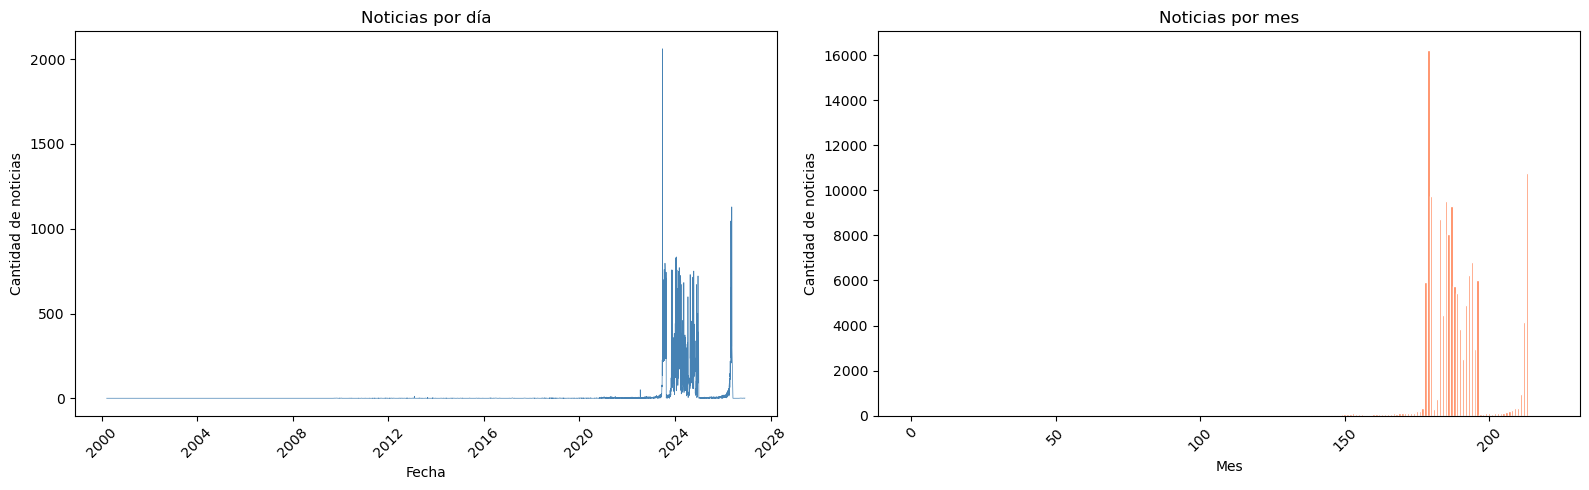

In [26]:
# Distribución de fechas
fig, axes = plt.subplots(1, 2, figsize=(16, 5))

# Histograma de densidad de fechas por día
dates_valid = df['date'].dropna()
daily_counts = dates_valid.dt.date.value_counts().sort_index()

axes[0].plot(daily_counts.index, daily_counts.values, linewidth=0.5, color='steelblue')
axes[0].set_title('Noticias por día')
axes[0].set_xlabel('Fecha')
axes[0].set_ylabel('Cantidad de noticias')
axes[0].tick_params(axis='x', rotation=45)

# Distribución por mes
monthly_counts = dates_valid.dt.to_period('M').value_counts().sort_index()
axes[1].bar(range(len(monthly_counts)), monthly_counts.values, color='coral', edgecolor='white')
axes[1].set_title('Noticias por mes')
axes[1].set_xlabel('Mes')
axes[1].set_ylabel('Cantidad de noticias')
axes[1].tick_params(axis='x', rotation=45)

plt.tight_layout()
plt.show()

### Limpieza de fechas

In [24]:
df = df.dropna(subset=['date']).copy()
df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
df.shape

(139996, 7)

In [44]:
df['year'] = df['date'].dt.year
df['month'] = df['date'].dt.month
df['day_of_week'] = df['date'].dt.day_name()

In [15]:
df["month"] = pd.Categorical(
    values=df["month"],
    categories=list(range(1, 12 + 1)),
    ordered=True
)
month_names = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']

In [16]:
month_number = df["month"].unique().categories.values.tolist()
month_number_to_name = {num: name for (num, name) in list(zip(month_number, month_names))}
df["month_name"] = df["month"].replace(month_number_to_name)

C:\Users\leomo\AppData\Local\Temp\ipykernel_21448\291968358.py:3: FutureWarning: The behavior of Series.replace (and DataFrame.replace) with CategoricalDtype is deprecated. In a future version, replace will only be used for cases that preserve the categories. To change the categories, use ser.cat.rename_categories instead.
  df["month_name"] = df["month"].replace(month_number_to_name)


### Cantidad de noticias en el tiempo

In [45]:
df["year"].value_counts().sort_index()

year
2000        1
2002        2
2003        1
2007        2
2008        7
2009       26
2010       44
2011      118
2012      124
2013      143
2014       77
2015       86
2016       73
2017       57
2018      158
2019      172
2020      246
2021      872
2022     1115
2023    47173
2024    71348
2025     1547
2026    16604
Name: count, dtype: int64

## 4. Análisis por medio

### Deduplicación de medios

In [6]:
def extraer_dominio_limpio(texto):
    if pd.isna(texto) or not isinstance(texto, str):
        return ""
    
    # Si parece una URL o dominio, extraemos la parte limpia
    ext = tldextract.extract(texto)
    if ext.domain:
        # Unimos dominio + sufijo (ej: elmostrador.cl)
        return f"{ext.domain}.{ext.suffix}"
    
    # Si es texto plano (ej: "El Mostrador"), normalizamos el texto básico
    return utils.default_process(texto)

In [7]:
def optimizar_nombres_medios(df: pd.DataFrame, columna_origen: str = 'media_name') -> pd.DataFrame:
    """
    Normaliza y agrupa nombres de medios utilizando un enfoque optimizado
    basado en valores únicos, evitando errores de memoria (MemoryError).
    """
    start_time = time.time()
    print("Iniciando proceso de deduplicación de nombres de medios en el dataset...")
    print(f"\t1. Filas totales en el dataset: {len(df):,}")
    
    # ==========================================
    # FASE 1: Extraer y limpiar catálogo único
    # ==========================================
    # En lugar de procesar +200k filas, procesamos solo los valores únicos
    medios_unicos = df[columna_origen].dropna().unique()
    df_unicos = pd.DataFrame({columna_origen: medios_unicos})
    print(f"\t2. Nombres de medios únicos a analizar: {len(df_unicos):,}")

    df_unicos['clean_name'] = df_unicos[columna_origen].apply(extraer_dominio_limpio)

    # ==========================================
    # FASE 2: Emparejamiento (Fuzzy Matching)
    # ==========================================
    # Como len(df_unicos) es pequeño (ej. 2000-5000), usar el indexador Full es 
    # viable, pero SortedNeighbourhood es a prueba de balas incluso con 50k únicos.
    indexer = recordlinkage.index.SortedNeighbourhood('clean_name', window=15)
    pares = indexer.index(df_unicos)
    
    comparador = recordlinkage.Compare()
    # Usamos Jaro-Winkler. Umbral de 0.88 es un buen punto de partida
    comparador.string('clean_name', 'clean_name', method='jarowinkler', threshold=0.88, label='similitud')
    
    caracteristicas = comparador.compute(pares, df_unicos)
    
    # Filtramos pares que superaron el umbral
    matches = caracteristicas[caracteristicas['similitud'] == 1].index

    # ==========================================
    # FASE 3: Construcción del Diccionario
    # ==========================================
    mapeo_fusion = {}
    
    for idx1, idx2 in matches:
        nombre_1 = df_unicos.loc[idx1, columna_origen]
        nombre_2 = df_unicos.loc[idx2, columna_origen]
        
        # Regla: el nombre más corto suele ser el "dominio base" sin subrutas
        if len(str(nombre_1)) <= len(str(nombre_2)):
            estandar, reemplazar = nombre_1, nombre_2
        else:
            estandar, reemplazar = nombre_2, nombre_1
            
        mapeo_fusion[reemplazar] = estandar

    print(f"\t3. Se identificaron {len(mapeo_fusion)} variaciones que serán agrupadas.")

    # ==========================================
    # FASE 4: Proyectar al Dataset Principal
    # ==========================================
    # Usamos .map() que está altamente optimizado en Pandas (en C)
    df[f"{columna_origen}_normalized"] = df[columna_origen].map(lambda x: mapeo_fusion.get(x, x))
    
    elapsed = time.time() - start_time
    print(f"\t4. Proceso completado en {elapsed:.2f} segundos.")
    
    return df

In [27]:
df = optimizar_nombres_medios(df=df, columna_origen="media_name")

1. Filas totales en el dataset: 139,996
2. Nombres de medios únicos a analizar: 1,759
3. Se identificaron 1646 variaciones que serán agrupadas.
4. Proceso completado en 0.74 segundos.


### Top de medios por frecuencia

In [17]:
def per_media_analysis(df:pd.DataFrame, column_name:str="media_name", top_k:int=20):
    print(f'Cantidad total de medios: {df[column_name].nunique():,}')
    print()
    
    # Top 20 medios
    media_counts = df[column_name].value_counts().head(top_k)
    print('=== Top 20 medios por cantidad de noticias ===')
    for i, (media, count) in enumerate(media_counts.items(), 1):
        pct = count / len(df) * 100
        print(f'{i:2d}. {media:30s}: {count:>8,} ({pct:5.1f}%)')
    print()
    
    # Distribución general
    media_val_counts = df[column_name].value_counts()
    print(f'Medio con más noticias: {media_val_counts.index[0]} ({media_val_counts.iloc[0]:,})')
    print(f'Medio con mediana de noticias: {media_val_counts.median():.0f}')
    print(f'Medio con menos noticias (top 100): {media_val_counts.iloc[-100]:,}')
    print(f'Medios con 1 sola noticia: {(media_val_counts == 1).sum():,}')

    return media_val_counts

In [20]:
media_val_counts = per_media_analysis(df, column_name="media_name_normalized")

Cantidad total de medios: 376

=== Top 20 medios por cantidad de noticias ===
 1. www.biobiochile.cl            :    8,268 (  5.9%)
 2. diarioeldia.cl                :    5,500 (  3.9%)
 3. cooperativa.cl                :    5,282 (  3.8%)
 4. portalinnova.cl               :    5,014 (  3.6%)
 5. www.emol.com                  :    4,061 (  2.9%)
 6. www.elrancaguino.cl           :    3,395 (  2.4%)
 7. www.diariolaunion.cl/enlace   :    3,197 (  2.3%)
 8. sabes.cl                      :    2,953 (  2.1%)
 9. elinformador.cl               :    2,900 (  2.1%)
10. www.meganoticias.cl           :    2,536 (  1.8%)
11. elproa.cl                     :    2,525 (  1.8%)
12. www.diariolaunion.cl          :    2,069 (  1.5%)
13. redgol.cl/rss/feed            :    2,017 (  1.4%)
14. prensaopal.cl                 :    1,998 (  1.4%)
15. www.emol.com/multimedia       :    1,975 (  1.4%)
16. lasnoticiasdemalleco.cl       :    1,727 (  1.2%)
17. www.elmostrador.cl/mercados   :    1,722 (  1.2%)
18. 

In [50]:
# Eliminamos las noticias del medio 'www.laizquierdadiario.pe' del data set de Chile
idx = df.loc[df["media_name_normalized"] == "www.laizquierdadiario.pe"].index
df.drop(index=idx, inplace=True)

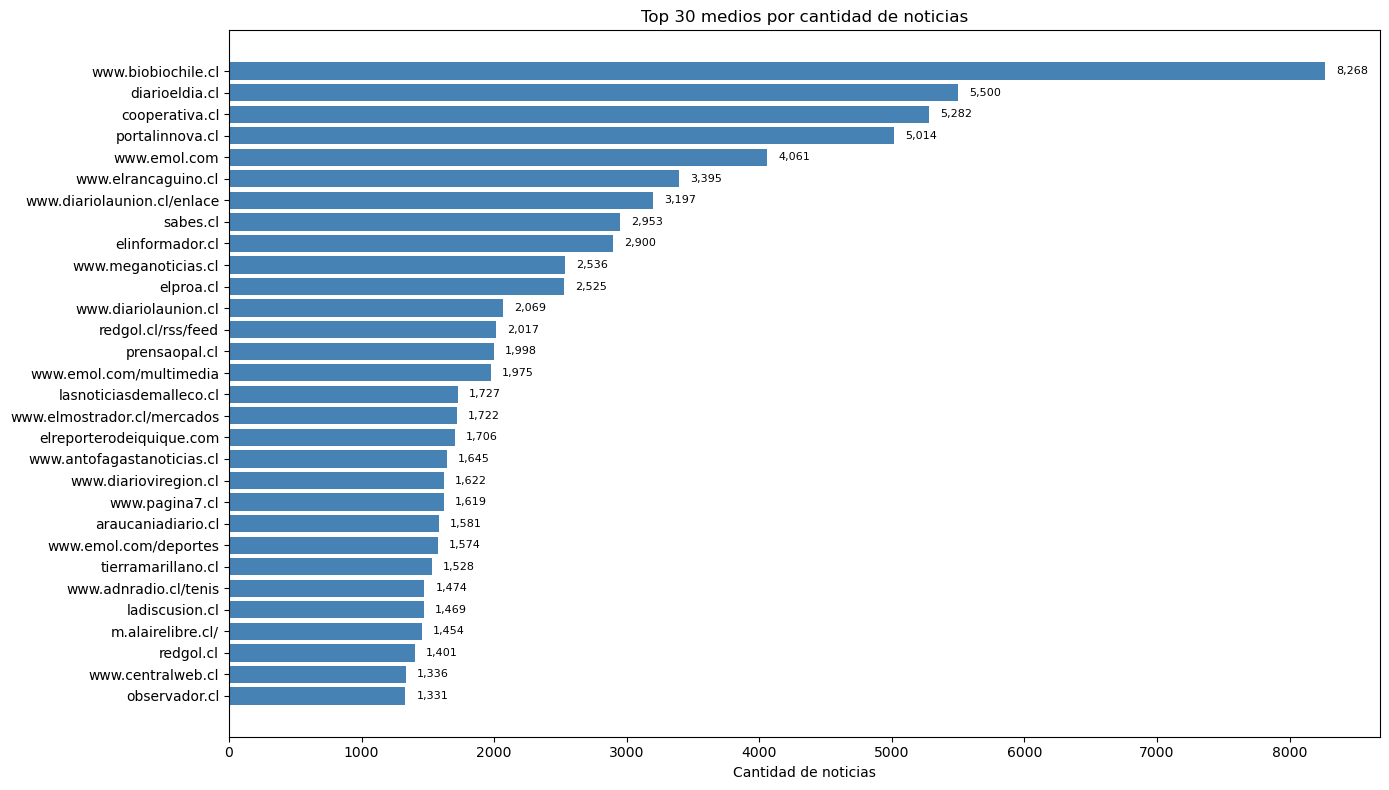

In [22]:
# Gráfico de barras de los top 30 medios
top_media = df['media_name_normalized'].value_counts().head(30)

fig, ax = plt.subplots(figsize=(14, 8))
bars = ax.barh(range(len(top_media)), top_media.values, color='steelblue')
ax.set_yticks(range(len(top_media)))
ax.set_yticklabels(top_media.index)
ax.set_xlabel('Cantidad de noticias')
ax.set_title('Top 30 medios por cantidad de noticias')
ax.invert_yaxis()

for bar, val in zip(bars, top_media.values):
    ax.text(bar.get_width() + max(top_media.values)*0.01, bar.get_y() + bar.get_height()/2, 
            f'{val:,}', va='center', fontsize=8)

plt.tight_layout()
plt.show()

### Proceso por *dataframe*

In [18]:
for selected_file in selected_files:
    print(f"Trabajando en {selected_file.stem}")
    df = pd.read_parquet(selected_file)
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    media_val_counts = per_media_analysis(df, column_name="media_name_normalized", top_k=25)
    media_val_counts.to_csv(eda_data_path / "per_media_statistics" / f"{selected_file.stem}_media_statistics.csv")

Trabajando en news_argentina
1. Filas totales en el dataset: 293,484
2. Nombres de medios únicos a analizar: 1,947
3. Se identificaron 1858 variaciones que serán agrupadas.
4. Proceso completado en 1.35 segundos.
Cantidad total de medios: 257

=== Top 20 medios por cantidad de noticias ===
 1. elle.clarin.com               :   32,070 ( 10.9%)
 2. www.infobae.com               :   21,020 (  7.2%)
 3. www.iprofesional.com/turismo  :   12,863 (  4.4%)
 4. servicios.lanacion.com.ar     :   10,055 (  3.4%)
 5. www.cronista.com/juegos       :    9,533 (  3.2%)
 6. www.eldestapeweb.com          :    8,707 (  3.0%)
 7. www.mejorinformado.com        :    7,198 (  2.5%)
 8. www.pagina12.com.ar           :    6,950 (  2.4%)
 9. www.eldiarioar.com            :    6,731 (  2.3%)
10. www.lmneuquen.com             :    6,364 (  2.2%)
11. www.ambito.com                :    6,210 (  2.1%)
12. www.elcordillerano.com.ar/region:    5,777 (  2.0%)
13. www.minutouno.com/boxeo-a242  :    4,614 (  1.6%)
14. e

### Características por medio

In [32]:
def per_media_features(df:pd.DataFrame, column_name:str="media_name", top_k:int=15):
    # Características por medio
    df['body_char_len'] = df['body'].str.len()
    df['body_word_count'] = df['body'].str.split().str.len()
    media_stats = df.groupby(column_name).agg(
        count=('id', 'count'),
        median_char_len=('body_char_len', 'median'),
        median_word_count=('body_word_count', 'median'),
        date_min=('date', 'min'),
        date_max=('date', 'max')
    ).reset_index()
    
    media_stats['date_span_days'] = (media_stats['date_max'] - media_stats['date_min']).dt.days
    
    print('=== Estadísticas por medio (top k por cantidad) ===')
    top_by_count = media_stats.nlargest(top_k, 'count')
    print(top_by_count[[column_name, 'count', 'median_char_len', 'median_word_count', 'date_span_days']].to_string(index=False))
    return media_stats

In [14]:
media_stats = per_media_features(df, column_name="media_name_normalized", top_k=20)

=== Estadísticas por medio (top k por cantidad) ===
      media_name_normalized  count  median_char_len  median_word_count  date_span_days
         www.biobiochile.cl   8268           2870.5              464.0            2759
             diarioeldia.cl   5500           3254.0              520.0            2792
             cooperativa.cl   5282           2869.0              463.0            1052
            portalinnova.cl   5014           3949.0              611.0            2305
               www.emol.com   4061           3323.0              540.0            3063
        www.elrancaguino.cl   3395           3214.0              532.0            1285
www.diariolaunion.cl/enlace   3197           3081.0              503.0            1082
                   sabes.cl   2953           2641.0              429.0            1138
            elinformador.cl   2900           3609.0              577.0            2188
        www.meganoticias.cl   2536           2599.0              424.0        

In [15]:
media_stats["percentage"] = (media_stats["count"] / media_stats["count"].sum()) * 100
media_stats.sort_values(by="count", ascending=False, inplace=True)
media_stats["percentage_cum_sum"] = media_stats["percentage"].cumsum()

In [16]:
media_stats.info()

<class 'pandas.core.frame.DataFrame'>
Index: 375 entries, 212 to 0
Data columns (total 9 columns):
 #   Column                 Non-Null Count  Dtype         
---  ------                 --------------  -----         
 0   media_name_normalized  375 non-null    object        
 1   count                  375 non-null    int64         
 2   median_char_len        375 non-null    float64       
 3   median_word_count      375 non-null    float64       
 4   date_min               375 non-null    datetime64[us]
 5   date_max               375 non-null    datetime64[us]
 6   date_span_days         375 non-null    int64         
 7   percentage             375 non-null    float64       
 8   percentage_cum_sum     375 non-null    float64       
dtypes: datetime64[us](2), float64(4), int64(2), object(1)
memory usage: 29.3+ KB


#### Proceso por *dataframe*

In [20]:
for selected_file in selected_files:
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    media_stats = per_media_features(df, column_name="media_name_normalized", top_k=20)
    media_stats["percentage"] = (media_stats["count"] / media_stats["count"].sum()) * 100
    media_stats.sort_values(by="count", ascending=False, inplace=True)
    media_stats["percentage_cum_sum"] = media_stats["percentage"].cumsum()
    media_stats.to_csv(eda_data_path / "per_media_statistics" / f"{selected_file.stem}_media_statistics.csv")

1. Filas totales en el dataset: 252,645
2. Nombres de medios únicos a analizar: 1,798
3. Se identificaron 1718 variaciones que serán agrupadas.
4. Proceso completado en 1.06 segundos.
=== Estadísticas por medio (top k por cantidad) ===
             media_name_normalized  count  median_char_len  median_word_count  date_span_days
                   elle.clarin.com  31979           4190.0              696.0            1905
                   www.infobae.com  21020           4004.5              634.0            1356
         servicios.lanacion.com.ar   9971           3987.0              652.0            3316
           www.cronista.com/juegos   9529           3028.0              486.0            2077
              www.eldestapeweb.com   8707           3317.0              546.0            1238
            www.mejorinformado.com   7188           2579.0              415.0            1472
                www.eldiarioar.com   6784           4934.5              790.0            6218
            

## 5. Análisis de autores

In [5]:
print(f'Noticias sin autor: {df["author"].isna().sum():,}')
print(f'Noticias con autor: {df["author"].notna().sum():,}')
print(f'Porcentaje sin autor: {df["author"].isna().mean()*100:.1f}%')
print()

authors = df['author'].dropna().unique()
print(f'Cantidad de autores únicos: {len(authors):,}')
print()

author_counts = df['author'].value_counts().head(20)
print('=== Top 20 autores ===')
for i, (author, count) in enumerate(author_counts.items(), 1):
    pct = count / df['author'].notna().sum() * 100
    print(f'{i:2d}. {str(author):30s}: {count:>8,} ({pct:5.2f}%)')
print()

author_val_counts = df['author'].value_counts()
print(f'Autor con más artículos: {author_val_counts.index[0]} ({author_val_counts.iloc[0]:,})')
print(f'Autor con mediana de artículos: {author_val_counts.median():.1f}')
print(f'Autores con 1 solo artículo: {(author_val_counts == 1).sum():,}')

Noticias sin autor: 76,195
Noticias con autor: 110,786
Porcentaje sin autor: 40.8%

Cantidad de autores únicos: 6,507

=== Top 20 autores ===
 1. El Mercurio S.A.P.            :    7,873 ( 7.11%)
 2. Portal Innova Grupo Prensa Digital:    4,937 ( 4.46%)
 3. Diario Estrategia Estrategia On Line:    3,474 ( 3.14%)
 4. Publicado Por                 :    2,553 ( 2.30%)
 5. Diario Estrategia Europa Press:    2,345 ( 2.12%)
 6. Krishna Cárdenas              :    1,933 ( 1.74%)
 7. Please Enter Your Name Here   :    1,881 ( 1.70%)
 8. Francisco Martorell           :    1,604 ( 1.45%)
 9. Colaborador Colaborador       :    1,595 ( 1.44%)
10. Compañia Chilena De Comunicaciones:    1,550 ( 1.40%)
11. Redacción El Rancagüino       :    1,369 ( 1.24%)
12. Central Web                   :    1,336 ( 1.21%)
13. Biobio Chile                  :    1,201 ( 1.08%)
14. Wdesign.Cl - Diseñweb Profesional:    1,173 ( 1.06%)
15. Edición El America.Cl Hernan Ordenes:    1,094 ( 0.99%)
16. Posted By            

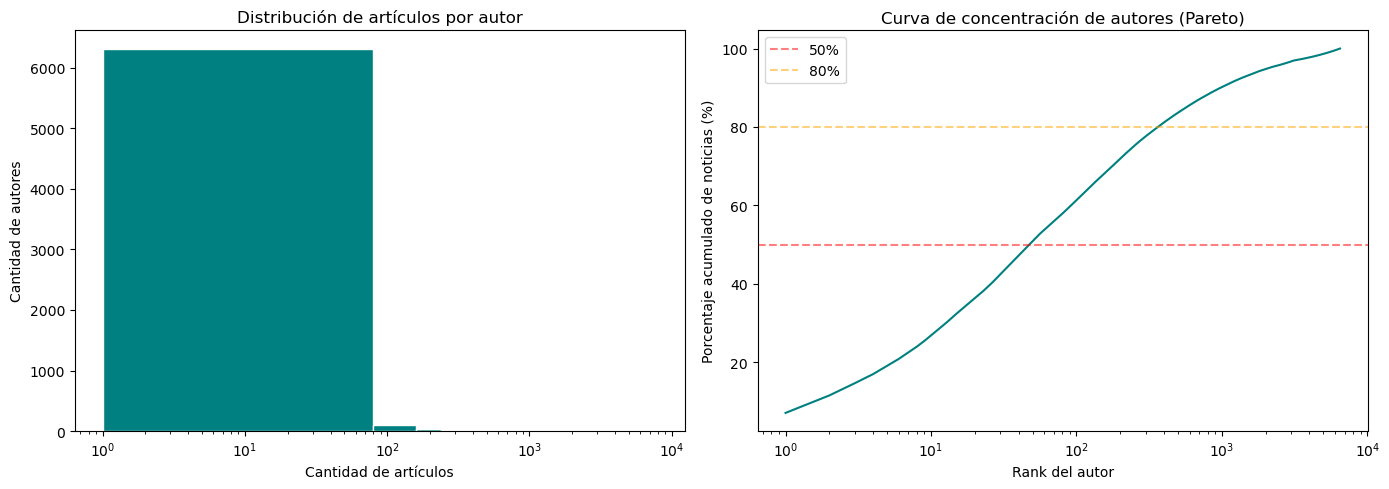

In [6]:
author_article_counts = df['author'].value_counts()

fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(author_article_counts.values, bins=100, color='teal', edgecolor='white')
axes[0].set_title('Distribución de artículos por autor')
axes[0].set_xlabel('Cantidad de artículos')
axes[0].set_ylabel('Cantidad de autores')
axes[0].set_xscale('log')

cumulative = author_article_counts.cumsum() / author_article_counts.sum() * 100
axes[1].plot(range(1, len(cumulative) + 1), cumulative.values, color='teal', linewidth=1.5)
axes[1].set_title('Curva de concentración de autores (Pareto)')
axes[1].set_xlabel('Rank del autor')
axes[1].set_ylabel('Porcentaje acumulado de noticias (%)')
axes[1].set_xscale('log')
axes[1].axhline(50, color='red', linestyle='--', alpha=0.5, label='50%')
axes[1].axhline(80, color='orange', linestyle='--', alpha=0.5, label='80%')
axes[1].legend()

plt.tight_layout()
plt.show()

### Proceso por *dataframe*

In [21]:
for selected_file in selected_files:
    print(f"Trabajando en {selected_file.stem}")
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = df.drop_duplicates(subset="body_hash")
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    top_author_val_counts = df['author'].value_counts().reset_index()
    total_counts = top_author_val_counts["count"].sum()
    top_author_val_counts["porcentaje"] = (top_author_val_counts["count"] / total_counts) * 100
    top_author_val_counts["porcentaje_acumulado"] = top_author_val_counts["porcentaje"].cumsum()
    top_author_val_counts = top_author_val_counts.head(40).round(2)
    print(top_author_val_counts.to_markdown())
    output_path = eda_data_path / "authors" / "raw_counts" / f"{selected_file.stem}_top_40_authors.csv"
    top_author_val_counts.to_csv(output_path, index=False)

Trabajando en news_argentina
1. Filas totales en el dataset: 252,645
2. Nombres de medios únicos a analizar: 1,798
3. Se identificaron 1718 variaciones que serán agrupadas.
4. Proceso completado en 1.14 segundos.
|    | author                                                                                                                                                |   count |   porcentaje |   porcentaje_acumulado |
|---:|:------------------------------------------------------------------------------------------------------------------------------------------------------|--------:|-------------:|-----------------------:|
|  0 | Redacción Clarín                                                                                                                                      |   16020 |         8.78 |                   8.78 |
|  1 | El Destape                                                                                                                                            |  

### Limpieza

In [22]:
def generar_datos_sankey_autoria(df: pd.DataFrame, country_name: str) -> dict:
    """
    Limpia, categoriza e infiere el género de la columna 'author'.
    Retorna un diccionario en formato Nodos y Enlaces listo para D3.js Sankey.
    """
    print(f"--- Procesando dataset de {country_name} ({len(df):,} filas) ---")
    
    # 1. Inicializar el detector de género
    # Usamos case_sensitive=False para mayor flexibilidad, pero le pasaremos capitalizado
    gd = gender.Detector()
    
    # Copia para no mutar el original
    dff = df[['author']].copy()
    
    # ==========================================
    # FASE 1: Limpieza Agresiva (Pre-procesamiento)
    # ==========================================
    def limpiar_texto(texto):
        if pd.isna(texto) or not isinstance(texto, str):
            return ""
        
        t = texto.lower().strip()
        
        # Eliminar basura de código HTML/CSS (.wp-block, class, img...)
        t = re.sub(r'(\.wp-block-|class|display inline|img he|post\.author).*', '', t)
        
        # Eliminar prefijos y textos de interfaz
        t = re.sub(r'(escrito por|publicado por|posted by|tema por|por favor ingrese su nombre aqu[íi]|please enter your name here)', '', t)
        
        # Eliminar caracteres extraños
        t = re.sub(r'[^a-záéíóúñü\s]', '', t)
        
        return t.strip()

    dff['author_clean'] = dff['author'].apply(limpiar_texto)

    # ==========================================
    # FASE 2: Categorización Heurística
    # ==========================================
    def categorizar_tipo(texto):
        if not texto:
            return "Anónimo"
        
        # Lista de agencias conocidas en Iberoamérica
        agencias = ['europa press', 'reuters', 'efe', 'afp', 'ap', 'agencia', 'noticias argentinas', 'getty']
        if any(a in texto for a in agencias):
            return "Agencia"
        
        # Lista de términos que denotan falta de firma personal
        anonimos = ['redaccion', 'redacción', 'admin', 'editor', 'staff', 'colaborador', 
                    'diario', 'prensa', 'tribuna', 'mercurio', 'portal', 'noticias', 'digital']
        if any(a in texto for a in anonimos):
            return "Anónimo"
        
        return "Firmado"

    dff['categoria'] = dff['author_clean'].apply(categorizar_tipo)

    # ==========================================
    # FASE 3: Inferencia de Género (Solo a los Firmados)
    # ==========================================
    def inferir_genero(row):
        if row['categoria'] != "Firmado":
            return "N/A"
        
        texto = row['author_clean']
        if not texto: return "Mixto/Desconocido"
        
        # Extraemos la primera palabra como posible nombre de pila
        primer_nombre = texto.split()[0].capitalize()
        
        # Inferencia
        guess = gd.get_gender(primer_nombre)
        
        if guess in ['male', 'mostly_male']:
            return "Hombre"
        elif guess in ['female', 'mostly_female']:
            return "Mujer"
        else:
            return "Mixto/Desconocido"

    dff['genero'] = dff.apply(inferir_genero, axis=1)

    # ==========================================
    # FASE 4: Agregación Matemática para Sankey
    # ==========================================
    total_noticias = len(dff)
    
    # Conteos Nivel 1 (Total -> Tipo)
    count_agencia = len(dff[dff['categoria'] == 'Agencia'])
    count_anonimo = len(dff[dff['categoria'] == 'Anónimo'])
    count_firmado = len(dff[dff['categoria'] == 'Firmado'])
    
    # Conteos Nivel 2 (Firmado -> Género)
    firmados_df = dff[dff['categoria'] == 'Firmado']
    count_hombre = len(firmados_df[firmados_df['genero'] == 'Hombre'])
    count_mujer = len(firmados_df[firmados_df['genero'] == 'Mujer'])
    count_mixto = len(firmados_df[firmados_df['genero'] == 'Mixto/Desconocido'])

    # ==========================================
    # FASE 5: Construcción de la Estructura JSON (Nodos y Enlaces)
    # ==========================================
    # Definimos los IDs de los nodos para D3.js (basado en índice)
    # 0: Total Noticias
    # 1: Agencia, 2: Anónimo, 3: Firmado
    # 4: Hombre, 5: Mujer, 6: Mixto/Desconocido
    
    sankey_data = {
        "country": country_name,
        "nodes": [
            {"node": 0, "name": "Total Noticias"},
            {"node": 1, "name": "Agencias"},
            {"node": 2, "name": "Redacción / Anónimo"},
            {"node": 3, "name": "Periodista Firmante"},
            {"node": 4, "name": "Hombre"},
            {"node": 5, "name": "Mujer"},
            {"node": 6, "name": "No Identificado"}
        ],
        "links": [
            # Nivel 1
            {"source": 0, "target": 1, "value": count_agencia},
            {"source": 0, "target": 2, "value": count_anonimo},
            {"source": 0, "target": 3, "value": count_firmado},
            # Nivel 2 (Solo sale del nodo 3 "Firmado")
            {"source": 3, "target": 4, "value": count_hombre},
            {"source": 3, "target": 5, "value": count_mujer},
            {"source": 3, "target": 6, "value": count_mixto}
        ]
    }
    
    return sankey_data

In [17]:
data_for_sankey_plot = generar_datos_sankey_autoria(df=df, country_name="Chile")

--- Procesando dataset de Chile (186,981 filas) ---


In [18]:
data_for_sankey_plot

{'country': 'Chile',
 'nodes': [{'node': 0, 'name': 'Total Noticias'},
  {'node': 1, 'name': 'Agencias'},
  {'node': 2, 'name': 'Redacción / Anónimo'},
  {'node': 3, 'name': 'Periodista Firmante'},
  {'node': 4, 'name': 'Hombre'},
  {'node': 5, 'name': 'Mujer'},
  {'node': 6, 'name': 'No Identificado'}],
 'links': [{'source': 0, 'target': 1, 'value': 12163},
  {'source': 0, 'target': 2, 'value': 113063},
  {'source': 0, 'target': 3, 'value': 61755},
  {'source': 3, 'target': 4, 'value': 24819},
  {'source': 3, 'target': 5, 'value': 14129},
  {'source': 3, 'target': 6, 'value': 22807}]}

#### Proceso por *DataFrame*

In [23]:
for selected_file in selected_files:
    print(f"Procesando {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.drop_duplicates(subset="body_hash")
    sankey_plot_data = generar_datos_sankey_autoria(df=df, country_name=selected_file.stem.partition("_")[-1].title())
    output_path = eda_data_path / "authors" / "sankey" / f"{selected_file.stem}_authorship_analysis.json"
    with open(output_path, "w", encoding="utf-8") as out_file:
        json.dump(sankey_plot_data, out_file, indent=2)
    print()

Procesando news_argentina...
--- Procesando dataset de Argentina (293,484 filas) ---

Procesando news_chile...
--- Procesando dataset de Chile (206,222 filas) ---

Procesando news_espana...
--- Procesando dataset de Espana (466,443 filas) ---

Procesando news_mexico...
--- Procesando dataset de Mexico (213,102 filas) ---



## 6. Análisis básico de textos

In [69]:
# Longitud de los textos (caracteres)
df['body_char_len'] = df['body'].str.len()

# Estimación de palabras (separando por espacios)
df['body_word_count'] = df['body'].str.split().str.len()

# Estadísticas descriptivas
print('=== Longitud de textos (caracteres) ===')
print(df['body_char_len'].describe())
print()
print('=== Cantidad de palabras ===')
print(df['body_word_count'].describe())

=== Longitud de textos (caracteres) ===
count    186981.000000
mean       4084.481557
std        3793.931832
min        1193.000000
25%        2385.000000
50%        3108.000000
75%        4383.000000
max      100000.000000
Name: body_char_len, dtype: float64

=== Cantidad de palabras ===
count    186981.000000
mean        657.314150
std         606.997253
min         301.000000
25%         385.000000
50%         499.000000
75%         701.000000
max       16465.000000
Name: body_word_count, dtype: float64


In [70]:
percentiles = [1, 5, 10, 25, 50, 75, 90, 95, 99]
print('=== Percentiles de longitud de textos (caracteres) ===')
for p in percentiles:
    print(f'{p:2d}° percentil: {df["body_char_len"].quantile(p/100):.0f}')
print()
print('=== Percentiles de cantidad de palabras ===')
for p in percentiles:
    print(f'{p:2d}° percentil: {df["body_word_count"].quantile(p/100):.0f}')

=== Percentiles de longitud de textos (caracteres) ===
 1° percentil: 1838
 5° percentil: 1968
10° percentil: 2071
25° percentil: 2385
50° percentil: 3108
75° percentil: 4383
90° percentil: 6483
95° percentil: 9105
99° percentil: 19593

=== Percentiles de cantidad de palabras ===
 1° percentil: 310
 5° percentil: 321
10° percentil: 337
25° percentil: 385
50° percentil: 499
75° percentil: 701
90° percentil: 1042
95° percentil: 1475
99° percentil: 3163


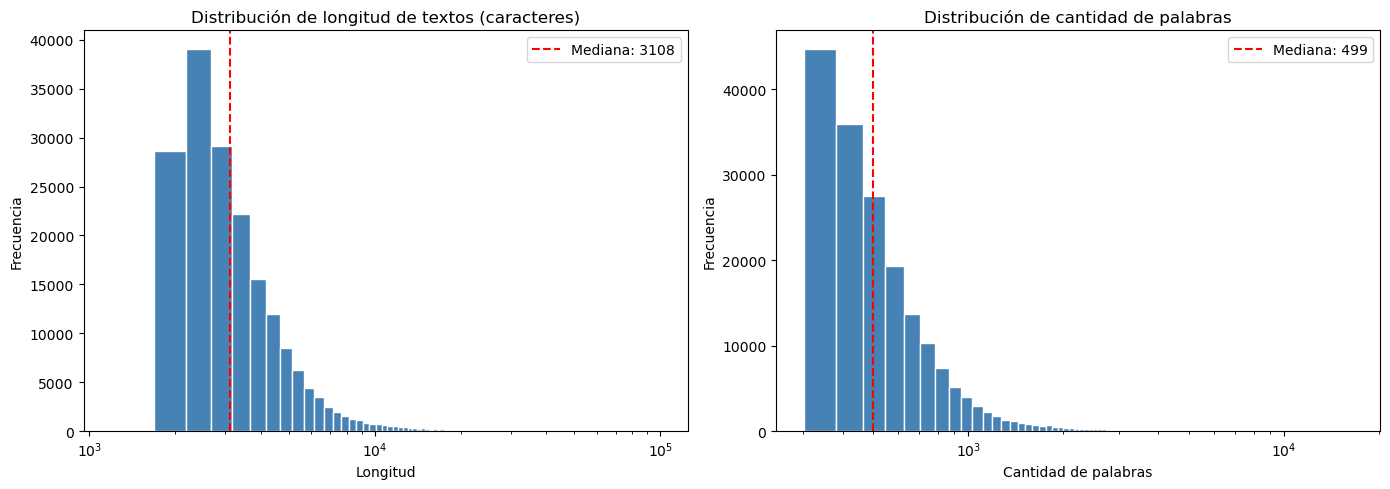

In [71]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['body_char_len'], bins=200, color='steelblue', edgecolor='white')
axes[0].set_title('Distribución de longitud de textos (caracteres)')
axes[0].set_xlabel('Longitud')
axes[0].set_ylabel('Frecuencia')
axes[0].axvline(df['body_char_len'].median(), color='red', linestyle='--', label=f'Mediana: {df["body_char_len"].median():.0f}')
axes[0].legend()
axes[0].set_xscale('log')

axes[1].hist(df['body_word_count'], bins=200, color='steelblue', edgecolor='white')
axes[1].set_title('Distribución de cantidad de palabras')
axes[1].set_xlabel('Cantidad de palabras')
axes[1].set_ylabel('Frecuencia')
axes[1].axvline(df['body_word_count'].median(), color='red', linestyle='--', label=f'Mediana: {df["body_word_count"].median():.0f}')
axes[1].legend()
axes[1].set_xscale('log')

plt.tight_layout()
plt.show()

## 7. Detección de outliers en textos

In [33]:
short_mask = df['body_word_count'] < 10
print(f'=== Textos con menos de 10 palabras: {short_mask.sum()} ===')
if short_mask.any():
    print(df.loc[short_mask, ['id', 'media_name', 'body']].head(10).to_string())
print()

q99 = df['body_word_count'].quantile(0.99)
long_mask = df['body_word_count'] > q99
print(f'=== Textos con más de {q99:.0f} palabras (top 1%): {long_mask.sum()} ===')
if long_mask.any():
    print(df.loc[long_mask, ['id', 'media_name', 'body_word_count']].head(10).to_string())

=== Textos con menos de 10 palabras: 0 ===

=== Textos con más de 3163 palabras (top 1%): 1870 ===
         id                       media_name  body_word_count
48   177363              www.24horas.cl/data             3379
49   177364              www.24horas.cl/data             3773
143  177900                   prensaopal.cl/             3393
157  177480  www.ciperchile.cl/investigacion             3822
181  177558           www.ciperchile.cl/blog             3624
259  177569        www.ciperchile.cl/premios             6986
260  177570        www.ciperchile.cl/premios             6631
261  177571        www.ciperchile.cl/premios             3852
263  177573        www.ciperchile.cl/premios             5052
264  177574        www.ciperchile.cl/premios             3293


## 8. Caracteres especiales y formato

In [72]:
df['has_accents'] = df['body'].apply(lambda x: bool(re.search(r'[áéíóúñü]', str(x))))
df['has_newlines'] = df['body'].apply(lambda x: '\n' in str(x))
df['has_html'] = df['body'].apply(lambda x: bool(re.search(r'<[^>]+>', str(x))))
df['has_urls'] = df['body'].apply(lambda x: bool(re.search(r'http[s]?://', str(x))))
df['has_emails'] = df['body'].apply(lambda x: bool(re.search(r'[\w.-]+@[\w.-]+', str(x))))
df['has_images'] = df['body'].apply(lambda x: bool(re.search(r'<img', str(x))))
df['has_tables'] = df['body'].apply(lambda x: bool(re.search(r'\|', str(x))))
df['has_bullet_lists'] = df['body'].apply(lambda x: bool(re.search(r'^\s*[-*•]\s', str(x), re.MULTILINE)))
df['has_numbered_lists'] = df['body'].apply(lambda x: bool(re.search(r'^\s*\d+\.\s', str(x), re.MULTILINE)))
df['has_quotes'] = df['body'].apply(lambda x: bool(re.search(r'["\u201c\u201d]', str(x))))

print('=== Presencia de elementos especiales en los textos ===')
# 'has_images'
for col in ['has_accents', 'has_newlines', 'has_html', 'has_urls', 'has_emails', 'has_tables', 'has_bullet_lists', 'has_numbered_lists', 'has_quotes']:
    print(f'{col}: {df[col].sum()} ({df[col].mean()*100:.1f}%)')

=== Presencia de elementos especiales en los textos ===
has_accents: 186895 (100.0%)
has_newlines: 186743 (99.9%)
has_html: 64 (0.0%)
has_urls: 6839 (3.7%)
has_emails: 2499 (1.3%)
has_tables: 3132 (1.7%)
has_bullet_lists: 2025 (1.1%)
has_numbered_lists: 1963 (1.0%)
has_quotes: 157369 (84.2%)


## 9. Estructura de párrafos

In [19]:
df['body_clean'] = df['body'].fillna('')
df['paragraph_count'] = df['body_clean'].apply(lambda x: len([p for p in x.split('\n\n') if p.strip()]))
df['line_count'] = df['body_clean'].apply(lambda x: len([l for l in x.split('\n') if l.strip()]))
df['words_per_paragraph'] = df['body_word_count'] / df['paragraph_count'].clip(lower=1)

print('=== Estadísticas de párrafos ===')
print(df['paragraph_count'].describe())
print()
print('=== Estadísticas de líneas ===')
print(df['line_count'].describe())
print()
print('=== Palabras promedio por párrafo ===')
print(df['words_per_paragraph'].describe())

=== Estadísticas de párrafos ===
count    186981.000000
mean         14.989304
std          17.986333
min           1.000000
25%           9.000000
50%          11.000000
75%          16.000000
max        2795.000000
Name: paragraph_count, dtype: float64

=== Estadísticas de líneas ===
count    186981.000000
mean         14.989304
std          17.986333
min           1.000000
25%           9.000000
50%          11.000000
75%          16.000000
max        2795.000000
Name: line_count, dtype: float64

=== Palabras promedio por párrafo ===
count    186981.000000
mean         49.850915
std          29.555445
min           2.544803
25%          35.642857
50%          45.875000
75%          59.000000
max        2137.000000
Name: words_per_paragraph, dtype: float64


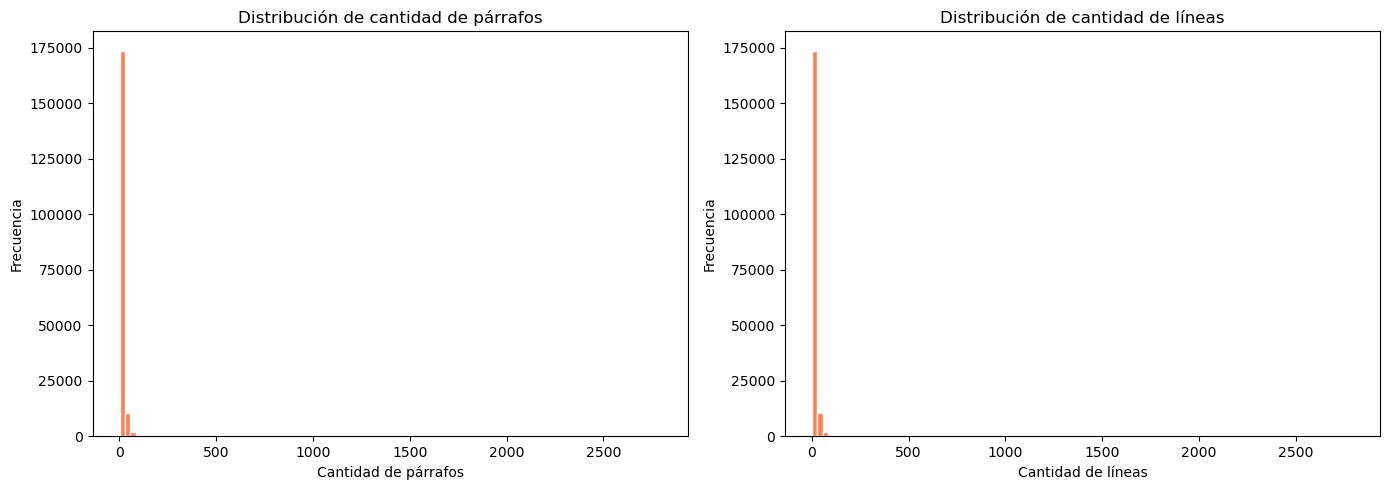

In [23]:
fig, axes = plt.subplots(1, 2, figsize=(14, 5))

axes[0].hist(df['paragraph_count'], bins=100, color='coral', edgecolor='white')
axes[0].set_title('Distribución de cantidad de párrafos')
axes[0].set_xlabel('Cantidad de párrafos')
axes[0].set_ylabel('Frecuencia')

axes[1].hist(df['line_count'], bins=100, color='coral', edgecolor='white')
axes[1].set_title('Distribución de cantidad de líneas')
axes[1].set_xlabel('Cantidad de líneas')
axes[1].set_ylabel('Frecuencia')

plt.tight_layout()
plt.show()

## 10. Características lingüísticas (muestreo)

In [24]:
try:
    _ = nltk.data.find('tokenizers/punkt')
    _ = nltk.data.find('corpora/stopwords')
except LookupError:
    nltk.download('punkt', quiet=True)
    nltk.download('stopwords', quiet=True)

stop_words_es = set(stopwords.words('spanish'))

def analyze_text_features(text):
    if pd.isna(text) or not isinstance(text, str) or not text.strip():
        return pd.Series([0, 0, 0, 0, 0, 0, 0])
    
    words = word_tokenize(text)
    words_lower = [w.lower() for w in words if w.isalpha()]
    sentences = sent_tokenize(text)
    unique_words = set(words_lower)
    non_stop_words = [w for w in words_lower if w not in stop_words_es]
    
    return pd.Series([
        len(words),
        len(unique_words),
        len(sentences),
        len(non_stop_words),
        len(unique_words) / len(words_lower) if words_lower else 0,
        len(words) / len(sentences) if sentences else 0,
        len(non_stop_words) / len(words_lower) if words_lower else 0,
    ])


def apply_linguistic_analysis(df:pd.DataFrame) -> pd.DataFrame:
    features = df['body'].apply(analyze_text_features)
    features.columns = ['total_tokens', 'unique_words', 'sentences', 'non_stop_words', 'type_token_ratio', 'avg_sentence_len', 'content_ratio']
    return features
# print('=== Estadísticas de características lingüísticas ===')
# print(features.describe().round(3))

### Análisis

In [58]:
sample_size = 100_000
sample_size = min(sample_size, len(df))
sample = df.sample(n=sample_size, random_state=42)
print('Analizando características lingüísticas...')
features = apply_linguistic_analysis(df=sample)
features_description = features.describe().round(3)
print(features_description)

Analizando características lingüísticas...
       total_tokens  unique_words   sentences  non_stop_words  \
count    100000.000    100000.000  100000.000      100000.000   
mean        714.230       274.710      22.036         322.627   
std         594.322       149.426      22.336         274.337   
min         323.000        20.000       1.000          89.000   
25%         436.000       193.000      12.000         197.000   
50%         560.000       234.000      17.000         254.000   
75%         777.000       304.000      24.000         351.000   
max       18316.000      3035.000     718.000       10566.000   

       type_token_ratio  avg_sentence_len  content_ratio  
count        100000.000        100000.000     100000.000  
mean              0.478            36.138          0.525  
std               0.062            13.679          0.035  
min               0.021             5.944          0.380  
25%               0.441            28.400          0.504  
50%              

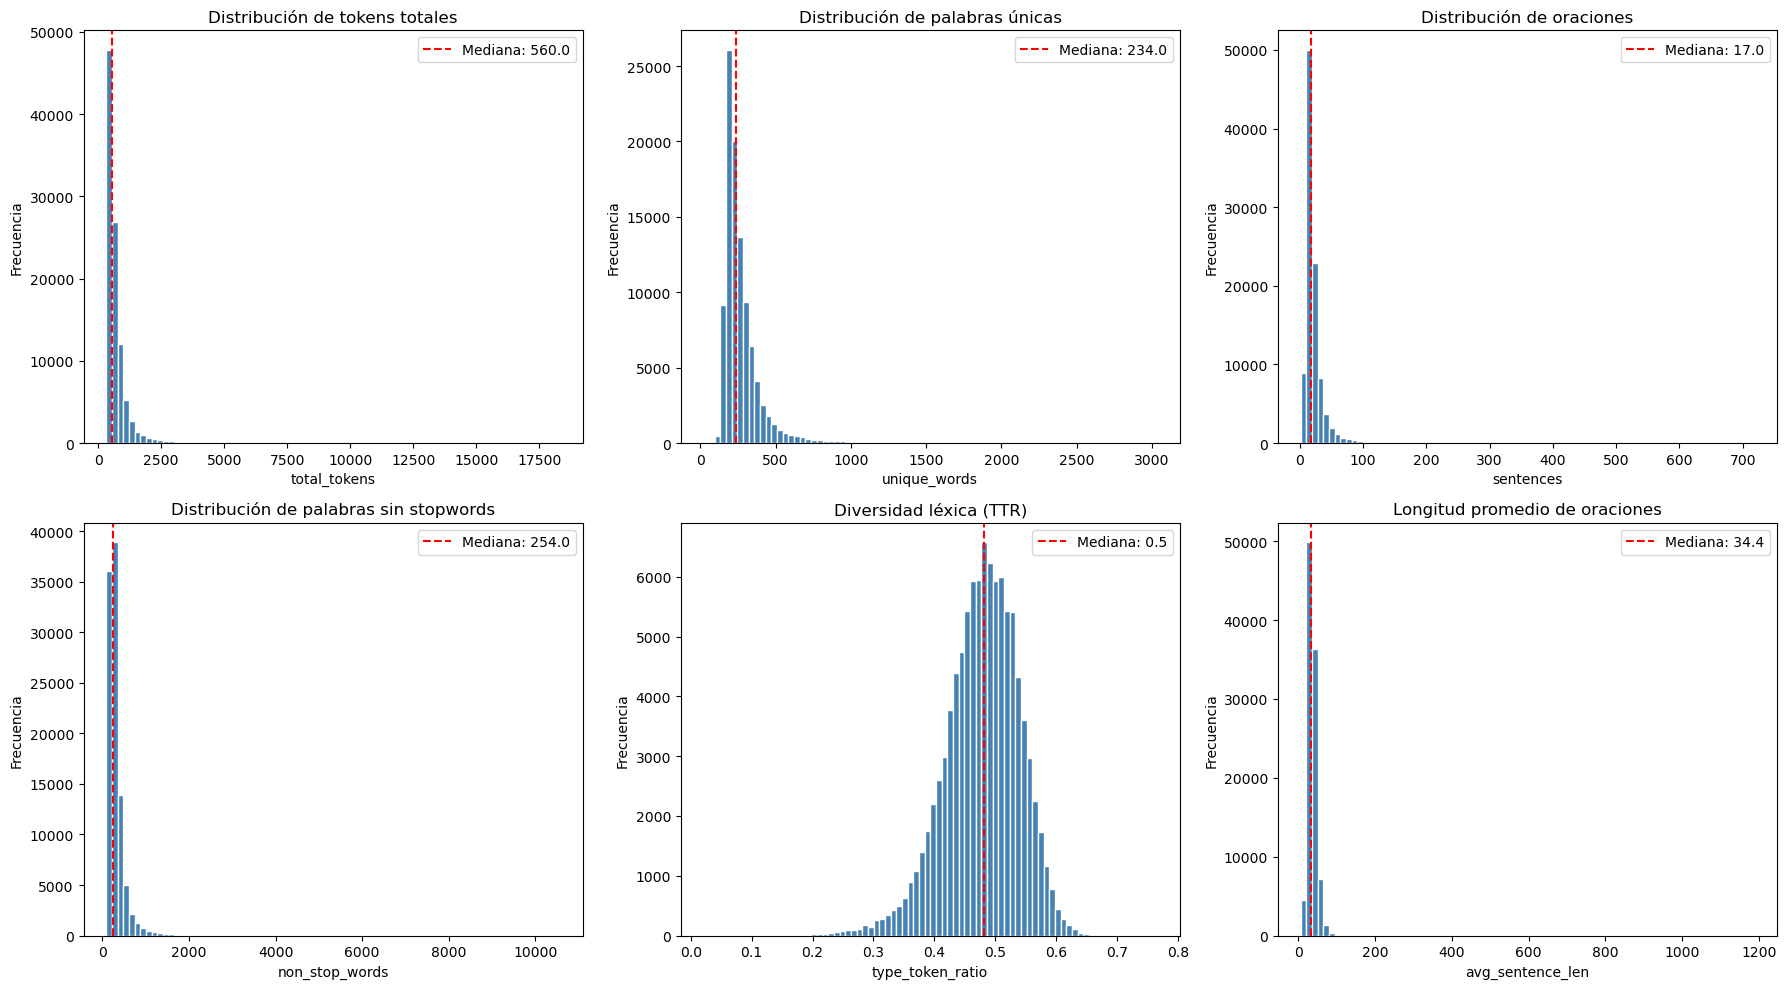

In [59]:
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

feature_plots = [
    ('total_tokens', 'Distribución de tokens totales'),
    ('unique_words', 'Distribución de palabras únicas'),
    ('sentences', 'Distribución de oraciones'),
    ('non_stop_words', 'Distribución de palabras sin stopwords'),
    ('type_token_ratio', 'Diversidad léxica (TTR)'),
    ('avg_sentence_len', 'Longitud promedio de oraciones'),
]

for i, (feat, title) in enumerate(feature_plots):
    axes[i].hist(features[feat], bins=80, color='steelblue', edgecolor='white')
    axes[i].set_title(title)
    axes[i].set_xlabel(feat)
    axes[i].set_ylabel('Frecuencia')
    axes[i].axvline(features[feat].median(), color='red', linestyle='--', 
                    label=f'Mediana: {features[feat].median():.1f}')
    axes[i].legend()

plt.tight_layout()
plt.show()

### Proceso por *dataframe*

In [33]:
sample_size = 170_000
for file in selected_files:
    print(f'Archivo cargado: {file.stem}')
    df = pd.read_parquet(file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    if len(df) == 0:
        continue
    print(f'Tamaño: {df.shape[0]:,} noticias x {df.shape[1]} columnas')
    sample_size = min(sample_size, len(df))
    sample = df.sample(n=sample_size, random_state=42)
    print('Analizando características lingüísticas...')
    features = apply_linguistic_analysis(df=sample)
    features_description = features.describe().round(3)
    features_description.to_csv(eda_data_path / "linguistic_characteristics" / f"{file.stem}_features.csv")
    print(features_description)
    print("\n\n" + "=" * 100 + "\n\n")

Archivo cargado: news_argentina
1. Filas totales en el dataset: 252,645
2. Nombres de medios únicos a analizar: 1,798
3. Se identificaron 1718 variaciones que serán agrupadas.
4. Proceso completado en 1.20 segundos.
Tamaño: 252,645 noticias x 8 columnas
Analizando características lingüísticas...
       total_tokens  unique_words   sentences  non_stop_words  \
count    170000.000    170000.000  170000.000      170000.000   
mean        767.752       299.304      27.648         350.237   
std         570.166       157.374      24.751         256.196   
min         320.000        10.000       1.000          85.000   
25%         453.000       201.000      15.000         208.000   
50%         605.000       253.000      21.000         278.000   
75%         873.000       342.000      31.000         400.000   
max       19418.000      4131.000    1047.000        9544.000   

       type_token_ratio  avg_sentence_len  content_ratio  
count        170000.000        170000.000     170000.000  

### Características lingüísticas por medio de comunicación

In [34]:
def linguistic_analysis_per_media(df: pd.DataFrame, column_name:str="media_name", top_k: int = 20, sample_size_per_media: int = 10000) -> pd.DataFrame:
    """
    Aplica el análisis de características lingüísticas del punto 10
    a las noticias de los top_k medios por frecuencia.
    
    Args:
        df: DataFrame con las noticias
        top_k: Número de medios a analizar
        sample_size_per_media: Muestra por medio para eficiencia
        
    Returns:
        DataFrame con las características lingüísticas por medio
    """
    # Obtener top_k medios por frecuencia
    top_media = df[column_name].value_counts().head(top_k).index.tolist()
    
    all_features = []
    
    for media in top_media:
        media_df = df[df[column_name] == media]
        if len(media_df) == 0:
            continue
        
        # Muestrear para eficiencia
        sample = media_df.sample(n=min(sample_size_per_media, len(media_df)), random_state=42)
        
        # Aplicar análisis lingüístico
        features = sample['body'].apply(analyze_text_features)
        features.columns = ['total_tokens', 'unique_words', 'sentences', 'non_stop_words', 
                           'type_token_ratio', 'avg_sentence_len', 'content_ratio']
        
        # Agregar columna de medio
        features[column_name] = media
        features['num_articles'] = len(media_df)
        
        all_features.append(features)
    
    result_df = pd.concat(all_features, ignore_index=True)
    
    # Imprimir resumen por medio
    print('=== Características lingüísticas por medio de comunicación ===')
    print(f'Análisis de los top {top_k} medios por frecuencia\n')
    
    for media in top_media:
        media_features = result_df[result_df[column_name] == media]
        if len(media_features) == 0:
            continue
        
        print(f'--- {media} ({media_features.iloc[0]["num_articles"]:,} artículos, {len(media_features):,} muestras analizadas) ---')
        print(media_features.describe().round(3))
        print()
    
    return result_df

In [8]:
# Aplicar análisis a los top 20 medios del dataset actual
linguistic_per_media_df = linguistic_analysis_per_media(df, top_k=20, sample_size_per_media=10000)

# Guardar resultados
output_path = eda_data_path / "linguistic_characteristics" / "per_media_features.csv"
output_path.parent.mkdir(parents=True, exist_ok=True)
linguistic_per_media_df.to_csv(output_path, index=False)
print(f'\nResultados guardados en: {output_path}')

=== Características lingüísticas por medio de comunicación ===
Análisis de los top 20 medios por frecuencia

--- www.biobiochile.cl (8,064 artículos, 8,064 muestras analizadas) ---
       total_tokens  unique_words  sentences  non_stop_words  \
count      8064.000      8064.000   8064.000        8064.000   
mean        678.602       256.750     23.078         303.637   
std         478.695       134.264     21.538         206.102   
min         334.000        66.000      6.000         112.000   
25%         425.000       179.000     13.000         191.000   
50%         529.000       215.000     17.000         238.000   
75%         737.000       286.000     24.000         334.000   
max        8323.000      1972.000    484.000        3440.000   

       type_token_ratio  avg_sentence_len  content_ratio  num_articles  
count          8064.000          8064.000       8064.000        8064.0  
mean              0.462            31.844          0.524        8064.0  
std               0.057

In [10]:
# Visualización comparativa de características lingüísticas por medio
top_media_list = df['media_name_normalized'].value_counts().head(20).index.tolist()
top_media_features = linguistic_per_media_df[linguistic_per_media_df['media_name'].isin(top_media_list)]

# Estadísticas resumidas por medio
summary_stats = top_media_features.groupby('media_name').agg(
    num_samples=('total_tokens', 'count'),
    mean_tokens=('total_tokens', 'mean'),
    median_tokens=('total_tokens', 'median'),
    mean_unique_words=('unique_words', 'mean'),
    mean_sentences=('sentences', 'mean'),
    mean_ttr=('type_token_ratio', 'mean'),
    mean_sent_len=('avg_sentence_len', 'mean'),
    mean_content_ratio=('content_ratio', 'mean')
).reset_index()

print('=== Resumen de características por medio (top 10) ===')
print(summary_stats.to_string(index=False))
print()

=== Resumen de características por medio (top 10) ===
                  media_name  num_samples  mean_tokens  median_tokens  mean_unique_words  mean_sentences  mean_ttr  mean_sent_len  mean_content_ratio
         diariodevaldivia.cl         1550   635.601290          510.5         270.223871       19.323871  0.512850      36.437855            0.538956
            diarioelranco.cl         1447   647.341396          591.0         257.114029       16.400138  0.468233      43.565028            0.520229
           diariolaquinta.cl         1537   660.399480          577.0         264.024073       17.299284  0.474371      40.488370            0.523775
              ladiscusion.cl         1461   683.983573          558.0         274.036277       18.084189  0.483786      40.226728            0.519373
       laizquierdadiario.com         1914  1249.900209          848.0         432.876698       40.220481  0.447337      33.066335            0.514683
     lasnoticiasdemalleco.cl         1699   55

In [ ]:
# Gráficos comparativos por medio
fig, axes = plt.subplots(2, 3, figsize=(18, 10))
axes = axes.flatten()

features_to_plot = [
    ('total_tokens', 'Tokens totales'),
    ('unique_words', 'Palabras únicas'),
    ('sentences', 'Oraciones'),
    ('type_token_ratio', 'Diversidad léxica (TTR)'),
    ('avg_sentence_len', 'Longitud promedio oración'),
    ('content_ratio', 'Proporción contenido'),
]

for idx, (feat, title) in enumerate(features_to_plot):
    data = top_media_features[top_media_features['media_name'].isin(top_media_list)]
    
    # Crear boxplot por medio
    media_data = [data[data['media_name'] == media][feat].values for media in top_media_list]
    
    bp = axes[idx].boxplot(media_data, labels=[m[:20] + '...' if len(m) > 20 else m for m in top_media_list],
                           patch_artist=True, medianprops=dict(color='red', linewidth=2))
    
    # Colorear cajas
    colors = plt.cm.Set3(np.linspace(0, 1, len(top_media_list)))
    for patch, color in zip(bp['boxes'], colors):
        patch.set_facecolor(color)
        patch.set_alpha(0.7)
    
    axes[idx].set_title(title)
    axes[idx].set_xlabel('Medio')
    axes[idx].set_ylabel(feat)
    axes[idx].tick_params(axis='x', rotation=45)

fig.suptitle('Comparación de características lingüísticas por medio (top 10)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

### Proceso por *dataframe*

In [35]:
sample_size = 170_000
for selected_file in selected_files:
    print(f"Procesando {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    top_media_list = df['media_name_normalized'].value_counts().head(20).index.tolist()
    linguistic_per_media_df = linguistic_analysis_per_media(df, column_name="media_name_normalized", top_k=20, sample_size_per_media=sample_size)
    top_media_features = linguistic_per_media_df[linguistic_per_media_df['media_name_normalized'].isin(top_media_list)]
    
    # Estadísticas resumidas por medio
    summary_stats = top_media_features.groupby('media_name_normalized').agg(
        num_samples=('total_tokens', 'count'),
        mean_tokens=('total_tokens', 'mean'),
        median_tokens=('total_tokens', 'median'),
        mean_unique_words=('unique_words', 'mean'),
        mean_sentences=('sentences', 'mean'),
        mean_ttr=('type_token_ratio', 'mean'),
        mean_sent_len=('avg_sentence_len', 'mean'),
        mean_content_ratio=('content_ratio', 'mean')
    ).reset_index()
    summary_stats.to_csv(eda_data_path / "linguistic_characteristics" / f"{selected_file.stem}_features_per_media.csv")
    print('=== Resumen de características por medio (top 20) ===')
    print(summary_stats.to_string(index=False))
    print()

Procesando news_argentina...
1. Filas totales en el dataset: 252,645
2. Nombres de medios únicos a analizar: 1,798
3. Se identificaron 1718 variaciones que serán agrupadas.
4. Proceso completado en 1.19 segundos.
=== Características lingüísticas por medio de comunicación ===
Análisis de los top 20 medios por frecuencia

--- elle.clarin.com (31,979 artículos, 31,979 muestras analizadas) ---
       total_tokens  unique_words  sentences  non_stop_words  \
count     31979.000     31979.000  31979.000       31979.000   
mean        969.945       356.848     38.935         434.527   
std         600.719       168.979     29.827         266.655   
min         326.000        46.000      5.000         129.000   
25%         603.000       248.000     21.000         272.000   
50%         794.000       312.000     30.000         358.000   
75%        1155.000       423.000     46.000         519.000   
max       11543.000      2672.000    566.000        5206.000   

       type_token_ratio  avg_s

### Legibilidad

In [36]:
def calcular_escolaridad(puntaje_inflesz: float) -> float:
    """
    Mapea el puntaje INFLESZ a años de escolaridad requeridos
    usando interpolación lineal segmentada.
    """
    if puntaje_inflesz >= 80:
        return 6.0 - ((puntaje_inflesz - 80) / 20.0) * 2.0 # Rango 4 a 6
    elif puntaje_inflesz >= 65:
        return 8.0 - ((puntaje_inflesz - 65) / 15.0) * 2.0 # Rango 6 a 8
    elif puntaje_inflesz >= 55:
        return 12.0 - ((puntaje_inflesz - 55) / 10.0) * 4.0 # Rango 8 a 12
    elif puntaje_inflesz >= 40:
        return 16.0 - ((puntaje_inflesz - 40) / 15.0) * 4.0 # Rango 12 a 16
    else:
        # Menor a 40: Escala de 16 a 20+ años
        escolaridad = 16.0 + ((40 - puntaje_inflesz) / 40.0) * 4.0
        return min(escolaridad, 20.0) # Topeamos en 20 años (Postgrado avanzado)

def procesar_legibilidad(df: pd.DataFrame, pais: str, top_medios: int = 15, media_column_name: str = "media_name", muestras_por_medio: int = 150) -> str:
    """
    Toma el DataFrame de noticias, filtra los top medios, realiza un muestreo 
    estratificado y calcula el INFLESZ y la escolaridad.
    Devuelve un JSON formateado para D3.js.
    """
    print(f"[{pais}] Iniciando análisis de Legibilidad y Barrera de Cristal...")
    
    # 1. Limpieza y filtrado inicial
    df_clean = df.dropna(subset=['body', media_column_name]).copy()
    
    # Identificar los top N medios más frecuentes para que el gráfico sea relevante
    top_media_list = df_clean[media_column_name].value_counts().head(top_medios).index.tolist()
    df_top = df_clean[df_clean[media_column_name].isin(top_media_list)]
    
    # 2. Muestreo Estratificado (CRÍTICO PARA RENDIMIENTO D3.JS)
    # Evita renderizar 200k burbujas. 15 medios * 150 muestras = 2250 nodos.
    # Esta es la cantidad perfecta para que d3-force corra fluido a 60fps.
    df_sample = df_top.groupby(media_column_name).sample(
        n=muestras_por_medio, 
        replace=True # Usar replace=True por si algún medio top tiene menos de 150
    ).drop_duplicates(subset=['id']).copy()
    
    print(f"[{pais}] Muestra seleccionada: {len(df_sample)} noticias a evaluar.")

    # 3. Configuración de NLP
    dic_silabas = pyphen.Pyphen(lang='es')
    resultados = []
    
    # Expresión regular para limpiar puntuación al contar palabras
    word_pattern = re.compile(r'[a-záéíóúñü]+', re.IGNORECASE)

    # 4. Procesamiento iterativo
    for _, row in df_sample.iterrows():
        texto = str(row['body'])
        if len(texto.strip()) < 50:
            continue # Evitar textos basura muy cortos
            
        # Extraer un "Sample Text" para el Tooltip en la web.
        # Tomamos la primera oración como resumen del estilo.
        oraciones = sent_tokenize(texto)
        if not oraciones:
            continue
            
        sample_text = oraciones[0]
        # Si la primera oración es gigantesca, la truncamos para que no rompa el UI
        if len(sample_text) > 200:
            sample_text = sample_text[:197] + "..."

        # Métricas brutas
        palabras_brutas = word_tokenize(texto)
        palabras_validas = [p for p in palabras_brutas if word_pattern.fullmatch(p)]
        
        num_oraciones = len(oraciones)
        num_palabras = len(palabras_validas)
        
        if num_oraciones == 0 or num_palabras == 0:
            continue
            
        # Conteo de sílabas usando Pyphen
        # Pyphen devuelve la palabra separada por guiones ej: "mur-cié-la-go"
        num_silabas = sum([len(dic_silabas.inserted(p).split('-')) for p in palabras_validas])
        
        # 5. Cálculo de Fórmulas
        ratio_silabas_palabras = num_silabas / num_palabras
        ratio_palabras_oraciones = num_palabras / num_oraciones
        
        # Fórmula de Flesch-Szigriszt (Adaptación de Flesch para el español)
        inflesz = 206.835 - (62.3 * ratio_silabas_palabras) - ratio_palabras_oraciones
        
        # Mapeo a Años de Educación
        anios_edu = calcular_escolaridad(inflesz)
        
        resultados.append({
            'country': pais,
            'media_name': row[media_column_name],
            'inflesz_score': round(inflesz, 2),
            'years_education': round(anios_edu, 1),
            'sample_text': sample_text
        })
        
    # 6. Generación de JSON para D3
    df_resultados = pd.DataFrame(resultados)
    
    # Excluir outliers groseros (ej. errores de parseo con frases de 1000 palabras sin puntos)
    df_resultados = df_resultados[(df_resultados['years_education'] >= 6) & (df_resultados['years_education'] <= 22)]
    
    json_output = df_resultados.to_json(orient='records', force_ascii=False)
    print(f"[{pais}] Procesamiento exitoso. {len(df_resultados)} nodos generados.")
    
    return json_output

In [60]:
df = optimizar_nombres_medios(df=df, columna_origen="media_name")
df.columns

1. Filas totales en el dataset: 186,981
2. Nombres de medios únicos a analizar: 2,022
3. Se identificaron 1891 variaciones que serán agrupadas.
4. Proceso completado en 0.76 segundos.


Index(['id', 'media_name', 'url', 'date', 'author', 'body', 'body_hash',
       'media_name_normalized'],
      dtype='object')

In [63]:
json_results = procesar_legibilidad(
    df=df,
    pais="Chile",
    top_medios=25,
    media_column_name="media_name_normalized",
    muestras_por_medio=300
)

[Chile] Iniciando análisis de Legibilidad y Barrera de Cristal...
[Chile] Muestra seleccionada: 7112 noticias a evaluar.
[Chile] Procesamiento exitoso. 7090 nodos generados.


In [65]:
json_results[:500]

'[{"country":"Chile","media_name":"cooperativa.cl","inflesz_score":62.78,"years_education":8.9,"sample_text":"El Tribunal Oral en Lo Penal de Temuco dictó una sentencia de 17 años de cárcel contra Martín Pradenas, declarado culpable de dos delitos de violación y cinco de abusos sexuales."},{"country":"Chile","media_name":"cooperativa.cl","inflesz_score":40.0,"years_education":16.0,"sample_text":"Los líderes del G7 expresaron este viernes preocupación sobre las prácticas comerciales \\"injustas\\" d'

In [37]:
for selected_file in selected_files:
    df = pd.read_parquet(selected_file)
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    json_results = procesar_legibilidad(
        df=df,
        pais=selected_file.stem.partition("_")[-1].title(),
        top_medios=25,
        media_column_name="media_name_normalized",
        muestras_por_medio=500
    )
    output_path = eda_data_path / "linguistic_characteristics" / "readability_per_country_and_media" / f"{selected_file.stem}_readability_per_media.json"
    with open(output_path, "w", encoding="utf-8") as out_file:
        json.dump(json_results, out_file, indent=2)

1. Filas totales en el dataset: 293,484
2. Nombres de medios únicos a analizar: 1,947
3. Se identificaron 1858 variaciones que serán agrupadas.
4. Proceso completado en 1.50 segundos.
[Argentina] Iniciando análisis de Legibilidad y Barrera de Cristal...
[Argentina] Muestra seleccionada: 11898 noticias a evaluar.
[Argentina] Procesamiento exitoso. 11832 nodos generados.
1. Filas totales en el dataset: 206,222
2. Nombres de medios únicos a analizar: 3,013
3. Se identificaron 2846 variaciones que serán agrupadas.
4. Proceso completado en 1.68 segundos.
[Chile] Iniciando análisis de Legibilidad y Barrera de Cristal...
[Chile] Muestra seleccionada: 11417 noticias a evaluar.
[Chile] Procesamiento exitoso. 11373 nodos generados.
1. Filas totales en el dataset: 466,443
2. Nombres de medios únicos a analizar: 3,259
3. Se identificaron 3149 variaciones que serán agrupadas.
4. Proceso completado en 2.07 segundos.
[Espana] Iniciando análisis de Legibilidad y Barrera de Cristal...
[Espana] Muestra 

## 11. Palabras más frecuentes

In [38]:
def most_common_words(df:pd.DataFrame, sample_size=100_000, top_k:int=50):
    sample_size = min(50000, len(df))
    sample = df.sample(n=sample_size, random_state=42)
    
    stop_words_es = set(stopwords.words('spanish'))
    word_counts = Counter()
    
    for text in sample['body'].dropna():
        if isinstance(text, str) and text.strip():
            words = word_tokenize(text.lower())
            words_clean = [w for w in words if w.isalpha() and w not in stop_words_es and len(w) > 2]
            word_counts.update(words_clean)
    
    top_words = word_counts.most_common(top_k)
    print('=== Top 50 palabras más frecuentes (sin stopwords) ===')
    for word, count in top_words:
        print(f'{word}: {count:,}')
    return word_counts

In [ ]:
word_counts = most_common_words(df=df, sample_size=100_000)

In [ ]:
top_20 = word_counts.most_common(20)
words, counts = zip(*top_20)

fig, ax = plt.subplots(figsize=(12, 6))
bars = ax.barh(range(len(words)), counts, color='steelblue')
ax.set_yticks(range(len(words)))
ax.set_yticklabels(words)
ax.set_xlabel('Frecuencia')
ax.set_title('Top 20 palabras más frecuentes (sin stopwords, longitud > 2)')
ax.invert_yaxis()

for bar, count in zip(bars, counts):
    ax.text(bar.get_width() + max(counts)*0.01, bar.get_y() + bar.get_height()/2, 
            f'{count:,}', va='center', fontsize=9)

plt.tight_layout()
plt.show()

### Proceso por *dataframe*

In [39]:
sample_size = 170_000
for selected_file in selected_files:
    print(f"Procesando {selected_file.stem}")
    df = pd.read_parquet(selected_file)
    word_counts = most_common_words(df, sample_size=sample_size)
    output_path = eda_data_path / "N-grams" / f"{selected_file.stem}_unigram.json"
    with open(output_path, "w") as out_file:
        json.dump(word_counts.most_common(50), out_file)

Procesando news_argentina
=== Top 50 palabras más frecuentes (sin stopwords) ===
años: 54,403
argentina: 44,836
dos: 40,569
parte: 39,894
ser: 39,512
gobierno: 36,792
además: 35,893
año: 35,671
según: 35,296
nacional: 34,780
puede: 33,699
cada: 32,482
país: 31,010
vez: 28,044
tiempo: 27,011
personas: 26,583
mientras: 26,565
millones: 25,924
milei: 24,642
hace: 24,271
día: 23,839
tras: 23,816
hoy: 23,804
después: 23,701
momento: 23,444
presidente: 23,390
solo: 23,046
así: 23,014
trabajo: 22,923
luego: 22,855
lugar: 22,593
días: 22,590
ciudad: 22,311
gran: 22,133
vida: 21,795
tres: 21,618
ahora: 21,039
provincia: 20,968
cuenta: 20,850
mundo: 20,087
aunque: 20,009
caso: 19,990
primera: 19,955
bien: 19,907
manera: 19,735
mayor: 19,409
hacer: 19,374
mismo: 19,321
forma: 19,097
dijo: 18,423
Procesando news_chile
=== Top 50 palabras más frecuentes (sin stopwords) ===
chile: 53,803
años: 47,603
parte: 44,500
ser: 39,734
además: 38,080
personas: 38,075
región: 34,552
país: 34,269
año: 33,377
go

## 12. N-gramas

### Bigramas

In [40]:
def most_common_bigrams(df:pd.DataFrame, sample_size:int=100_000, top_k:int=50):
    bigram_counts = Counter()
    sample_size = min(sample_size, len(df))
    sample = df.sample(n=sample_size, random_state=42)
    
    stop_words_es = set(stopwords.words('spanish'))
    
    for text in sample['body'].dropna():
        if isinstance(text, str) and text.strip():
            words = word_tokenize(text.lower())
            words_clean = [w for w in words if w.isalpha() and w not in stop_words_es and len(w) > 2]
            bigrams = ngrams(words_clean, 2)
            bigram_counts.update(bigrams)
    
    print('=== Top 30 bigramas más frecuentes ===')
    for bigram, count in bigram_counts.most_common(top_k):
        print(f'{" ".join(bigram)}: {count:,}')
    return bigram_counts

In [ ]:
bigrams = most_common_bigrams(df=df, sample_size=100_000)

#### Proceso por *dataframe*

In [41]:
sample_size = 170_000
for selected_file in selected_files:
    print(f"Procesando {selected_file.stem}")
    df = pd.read_parquet(selected_file)
    bigram_counts = most_common_bigrams(df, sample_size=sample_size)
    output_path = eda_data_path / "N-grams" / f"{selected_file.stem}_bigrams.json"
    with open(output_path, "w") as out_file:
        json.dump(bigram_counts.most_common(50), out_file)

Procesando news_argentina
=== Top 30 bigramas más frecuentes ===
buenos aires: 54,899
javier milei: 31,705
redes sociales: 25,263
cada vez: 20,491
río negro: 18,078
año pasado: 15,733
millones dólares: 13,816
primera vez: 13,431
puede ser: 12,767
gobierno nacional: 12,756
inteligencia artificial: 12,724
provincia buenos: 12,184
fin semana: 11,952
hace años: 11,768
libertad avanza: 10,960
banco central: 10,855
últimos años: 10,718
san martín: 10,146
selección argentina: 9,817
ciudad buenos: 9,564
vaca muerta: 9,384
dos años: 9,118
presidente javier: 8,908
mismo tiempo: 8,671
jefe gabinete: 8,335
tipo cambio: 8,231
casa rosada: 8,058
millones pesos: 8,023
gran parte: 7,859
sergio massa: 7,329
patricia bullrich: 7,297
mar plata: 7,262
juntos cambio: 7,130
ministro economía: 7,127
muchas veces: 7,123
unión patria: 7,119
largo plazo: 6,999
sigue siendo: 6,898
derechos humanos: 6,777
forma parte: 6,752
nueva york: 6,705
dólar blue: 6,467
mauricio macri: 6,362
dni terminados: 6,193
lionel mes

### Trigramas

In [42]:
def most_common_trigrams(df:pd.DataFrame, sample_size:int=100_000, top_k:int=20, random_state:int=42):
    trigram_counts = Counter()
    sample_size = min(sample_size, len(df))
    sample = df.sample(n=sample_size, random_state=random_state)
    
    stop_words_es = set(stopwords.words('spanish'))
    
    for text in sample['body'].dropna():
        if isinstance(text, str) and text.strip():
            words = word_tokenize(text.lower())
            words_clean = [w for w in words if w.isalpha() and w not in stop_words_es and len(w) > 2]
            trigrams = ngrams(words_clean, 3)
            trigram_counts.update(trigrams)
    
    print('=== Top 20 trigramas más frecuentes ===')
    for trigram, count in trigram_counts.most_common(top_k):
        print(f'{" ".join(trigram)}: {count:,}')
    return trigram_counts

In [ ]:
trigrams = most_common_trigrams(df=df, sample_size=100_000)

#### Proceso por *dataframe*

In [43]:
sample_size = 170_000
for selected_file in selected_files:
    print(f"Procesando {selected_file.stem}")
    df = pd.read_parquet(selected_file)
    trigram_counts = most_common_trigrams(df, sample_size=sample_size, top_k=10)
    output_path = eda_data_path / "N-grams" / f"{selected_file.stem}_trigrams.json"
    with open(output_path, "w") as out_file:
        json.dump(trigram_counts.most_common(50), out_file)

Procesando news_argentina
=== Top 20 trigramas más frecuentes ===
provincia buenos aires: 12,140
ciudad buenos aires: 9,514
presidente javier milei: 8,829
gobierno javier milei: 4,329
horacio rodríguez larreta: 2,831
ministro economía luis: 2,401
san martín andes: 2,376
través redes sociales: 2,371
economía luis caputo: 2,322
ministerio público fiscal: 2,313
Procesando news_chile
=== Top 20 trigramas más frecuentes ===
ley propiedad intelectual: 7,642
algún medio comunicación: 7,566
blog redes sociales: 7,561
redes sociales indica: 7,561
delito sancionado ley: 7,559
vas utilizar contenido: 7,558
utilizar contenido diario: 7,558
contenido diario textos: 7,558
diario textos simplemente: 7,558
textos simplemente datos: 7,558
Procesando news_espana
=== Top 20 trigramas más frecuentes ===
sigue temas interesan: 9,611
alberto núñez feijóo: 4,851
gobierno pedro sánchez: 4,252
jul europa press: 3,155
isabel díaz ayuso: 2,865
presidente gobierno pedro: 2,216
josé luis rodríguez: 2,158
luis rodr

## 13. Categorías gramaticales (POS tagging)

In [44]:
pos_mapping = {
    'NN': 'Sust. sing.', 'NNS': 'Sust. pl.', 'NNP': 'Nombre propio', 'NNPS': 'N. propios pl.',
    'VB': 'Verbo base', 'VBD': 'Verbo pasado', 'VBG': 'Gerundio', 'VBN': 'Part. pasado', 'VBP': 'Verbo pres.', 'VBZ': 'Verbo 3ra pers.',
    'JJ': 'Adjetivo', 'JJR': 'Comparativo', 'JJS': 'Superlativo',
    'RB': 'Adverbio', 'RBR': 'Comp. adv.', 'RBS': 'Sup. adv.',
    'DT': 'Determinante', 'CC': 'Conjunción coord.', 'IN': 'Conjunción subord.',
    'PRP': 'Pron. pers.', 'PRP$': 'Pron. posesivo',
    'CD': 'Número cardinal', 'EX': 'Existencial', 'FW': 'Palabra extranjera',
    'UH': 'Interjección', 'SYM': 'Símbolo',
}

### Top *POS*

In [ ]:
try:
    _ = nltk.data.find('taggers/averaged_perceptron_tagger')
except LookupError:
    nltk.download('averaged_perceptron_tagger', quiet=True)
    nltk.download('averaged_perceptron_tagger_eng', quiet=True)

sample_size = min(100_000, len(df))
sample = df.sample(n=sample_size, random_state=42)

pos_counts = Counter()
total_words = 0
# revisar: https://www.nltk.org/api/nltk.tag.pos_tag_sents.html
for text in sample['body'].dropna():
    if isinstance(text, str) and text.strip():
        words = [w for w in word_tokenize(text) if w.isalpha()]
        if words:
            tagged = pos_tag(words)
            for _, tag in tagged:
                pos_counts[tag] += 1
                total_words += 1

pos_labels = [pos_mapping.get(tag, tag) for tag, _ in pos_counts.most_common()]
pos_values = [count for _, count in pos_counts.most_common()]
pos_percentages = [count/total_words*100 for count in pos_values]

print('=== Distribución de categorías gramaticales (POS tags) ===')
for label, pct in sorted(zip(pos_labels, pos_percentages), key=lambda x: -x[1]):
    print(f'{label}: {pct:.2f}%')

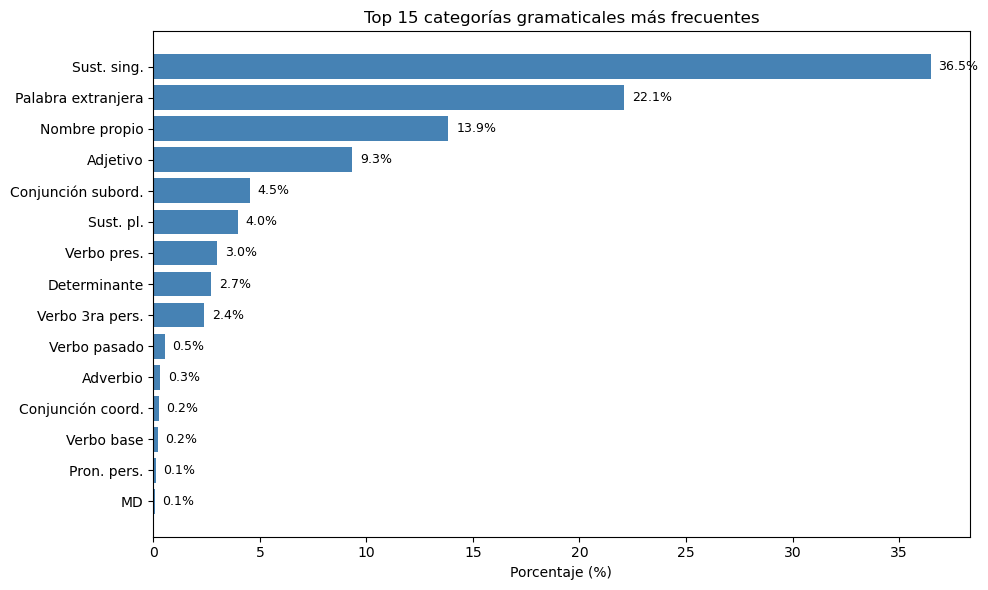

In [18]:
top_pos = sorted(pos_counts.items(), key=lambda x: -x[1])[:15]
tags, counts = zip(*top_pos)
labels = [pos_mapping.get(tag, tag) for tag in tags]
percentages = [count/total_words*100 for count in counts]

fig, ax = plt.subplots(figsize=(10, 6))
bars = ax.barh(range(len(labels)), percentages, color='steelblue')
ax.set_yticks(range(len(labels)))
ax.set_yticklabels(labels)
ax.set_xlabel('Porcentaje (%)')
ax.set_title('Top 15 categorías gramaticales más frecuentes')
ax.invert_yaxis()

for bar, pct in zip(bars, percentages):
    ax.text(bar.get_width() + max(percentages)*0.01, bar.get_y() + bar.get_height()/2, 
            f'{pct:.1f}%', va='center', fontsize=9)

plt.tight_layout()
plt.show()

#### Top *POS* por medio

In [45]:
def top_pos_per_media(df: pd.DataFrame, pos_mapping: dict = None, column_name: str = "media_name", 
                      top_k: int = 20, sample_size: int = 100_000) -> dict:
    """
    Extrae el Counter de POS tags para cada uno de los top_k medios.
    
    Returns:
        dict[str, Counter] → {media_name: pos_counts_Counter}
    """
    if not pos_mapping:
        raise ValueError("pos_mapping debe ser un objeto dict válido.")
    # Obtener top_k medios
    top_media = df[column_name].value_counts().head(top_k).index.tolist()
    
    pos_counts_global = Counter()  # acumulado global (como el código existente)
    pos_per_media = {}
    
    for media in top_media:
        media_df = df[df[column_name] == media]
        sample = media_df['body'].dropna().sample(n=min(sample_size, len(media_df)), random_state=42)
        
        media_pos = Counter()
        total = 0
        for text in sample:
            if isinstance(text, str) and text.strip():
                words = [w for w in word_tokenize(text) if w.isalpha()]
                if words:
                    tagged = pos_tag(words)
                    for _, tag in tagged:
                        media_pos[tag] += 1
                        pos_counts_global[tag] += 1
                        total += 1
        pos_per_media[media] = media_pos
    
    # Imprimir resumen global
    print('=== Distribución global de POS tags ===')
    for tag, count in pos_counts_global.most_common():
        label = pos_mapping.get(tag, tag)
        pct = count / sum(pos_counts_global.values()) * 100
        print(f'{label}: {pct:.2f}%')
    
    print()
    print(f'=== Top POS por medio (top {top_k}) ===')
    for media in top_media:
        if media in pos_per_media and pos_per_media[media]:
            total_media = sum(pos_per_media[media].values())
            print(f'\n--- {media} ({total_media:,} tokens totales) ---')
            for tag, count in pos_per_media[media].most_common():
                label = pos_mapping.get(tag, tag)
                pct = count / total_media * 100
                print(f'  {label}: {pct:.2f}%')
    
    return pos_per_media

In [13]:
pos_per_media = top_pos_per_media(df, pos_mapping=pos_mapping, column_name="media_name_normalized", top_k=20)

=== Distribución global de POS tags ===
Sust. sing.: 36.89%
Palabra extranjera: 21.98%
Nombre propio: 13.65%
Adjetivo: 9.35%
Conjunción subord.: 4.55%
Sust. pl.: 3.85%
Verbo pres.: 2.96%
Determinante: 2.72%
Verbo 3ra pers.: 2.40%
Verbo pasado: 0.53%
Adverbio: 0.34%
Conjunción coord.: 0.24%
Verbo base: 0.21%
Pron. pers.: 0.12%
MD: 0.06%
Comparativo: 0.05%
Part. pasado: 0.04%
Gerundio: 0.02%
RP: 0.02%
Comp. adv.: 0.01%
N. propios pl.: 0.01%
Número cardinal: 0.00%
PDT: 0.00%
Pron. posesivo: 0.00%
TO: 0.00%
Sup. adv.: 0.00%
WRB: 0.00%
WP: 0.00%
POS: 0.00%
Superlativo: 0.00%
WDT: 0.00%
Existencial: 0.00%
'': 0.00%
Interjección: 0.00%
Símbolo: 0.00%
WP$: 0.00%

=== Top POS por medio (top 20) ===

--- www.biobiochile.cl (4,807,640 tokens totales) ---
  Sust. sing.: 37.59%
  Palabra extranjera: 21.53%
  Nombre propio: 13.35%
  Adjetivo: 9.33%
  Conjunción subord.: 4.59%
  Sust. pl.: 3.70%
  Verbo pres.: 2.85%
  Determinante: 2.84%
  Verbo 3ra pers.: 2.50%
  Verbo pasado: 0.57%
  Adverbio: 0.34

In [46]:
sample_size = 170_000
for selected_file in selected_files:
    output_path = eda_data_path / "pos_tagging" / "top_pos_tags_per_country_and_media" / f"{selected_file.stem}_top_pos_per_media.json"
    if output_path.is_file():
        print(f"Dataset {selected_file.stem} ya procesado")
        continue
    print(f"Procesando {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    
    result = top_pos_per_media(df, column_name="media_name_normalized", pos_mapping=pos_mapping, top_k=25, sample_size=sample_size)
    
    # Convertir Counters a dicts para JSON
    result_serializable = {media: dict(counts) for media, counts in result.items()}
    with open(output_path, "w", encoding="utf-8") as f:
        json.dump(result_serializable, f, indent=2, ensure_ascii=False)
    
    print(f"Guardado en: {output_path}")
    print()

Procesando news_argentina...
1. Filas totales en el dataset: 252,645
2. Nombres de medios únicos a analizar: 1,798
3. Se identificaron 1718 variaciones que serán agrupadas.
4. Proceso completado en 1.43 segundos.
=== Distribución global de POS tags ===
Sust. sing.: 37.53%
Palabra extranjera: 21.07%
Nombre propio: 13.95%
Adjetivo: 9.46%
Conjunción subord.: 4.49%
Sust. pl.: 3.77%
Verbo pres.: 2.90%
Determinante: 2.65%
Verbo 3ra pers.: 2.50%
Verbo pasado: 0.55%
Adverbio: 0.34%
Verbo base: 0.22%
Conjunción coord.: 0.20%
Pron. pers.: 0.13%
MD: 0.07%
Comparativo: 0.04%
Part. pasado: 0.04%
Gerundio: 0.03%
RP: 0.02%
Comp. adv.: 0.01%
N. propios pl.: 0.01%
Número cardinal: 0.01%
PDT: 0.00%
Pron. posesivo: 0.00%
Sup. adv.: 0.00%
TO: 0.00%
WRB: 0.00%
WP: 0.00%
POS: 0.00%
Superlativo: 0.00%
WDT: 0.00%
Existencial: 0.00%
'': 0.00%
Interjección: 0.00%
Símbolo: 0.00%
WP$: 0.00%

=== Top POS por medio (top 25) ===

--- elle.clarin.com (26,414,095 tokens totales) ---
  Sust. sing.: 37.87%
  Palabra ext

### Adjetivos, sustantivos y verbos más frecuentes

In [47]:
try:
    _ = nltk.data.find('taggers/averaged_perceptron_tagger')
except LookupError:
    nltk.download('averaged_perceptron_tagger', quiet=True)
    nltk.download('averaged_perceptron_tagger_eng', quiet=True)

stop_words_es = set(stopwords.words('spanish'))

# Tags de Penn Treebank para cada categoría
ADJ_TAGS = {'JJ', 'JJR', 'JJS'}
NOUN_TAGS = {'NN', 'NNS', 'NNP', 'NNPS'}
VERB_TAGS = {'VB', 'VBD', 'VBG', 'VBN', 'VBP', 'VBZ'}

def extract_top_pos_words(texts, tag_set, n=20, sample_size=30000):
    """Extrae las palabras más frecuentes de una categoría POS."""
    sample = texts.dropna().sample(n=min(sample_size, len(texts)), random_state=42)
    word_counts = Counter()
    
    for text in sample:
        if isinstance(text, str) and text.strip():
            words = [w for w in word_tokenize(text) if w.isalpha()]
            if words:
                tagged = pos_tag(words)
                for word, tag in tagged:
                    word_lower = word.lower()
                    if tag in tag_set and word_lower not in stop_words_es and len(word_lower) > 2:
                        word_counts[word_lower] += 1
    
    return word_counts.most_common(n)

In [ ]:
# Extraer globalmente
print('Extrayendo adjetivos, sustantivos y verbos más frecuentes...')
top_adjectives = extract_top_pos_words(df['body'], ADJ_TAGS, n=20)
top_nouns = extract_top_pos_words(df['body'], NOUN_TAGS, n=20)
top_verbs = extract_top_pos_words(df['body'], VERB_TAGS, n=20)

print()
print('=== Top 20 adjetivos más frecuentes (sin stopwords) ===')
for i, (word, count) in enumerate(top_adjectives, 1):
    print(f'{i:2d}. {word:25s}: {count:>8,}')
print()

print('=== Top 20 sustantivos más frecuentes (sin stopwords) ===')
for i, (word, count) in enumerate(top_nouns, 1):
    print(f'{i:2d}. {word:25s}: {count:>8,}')
print()

print('=== Top 20 verbos más frecuentes (sin stopwords) ===')
for i, (word, count) in enumerate(top_verbs, 1):
    print(f'{i:2d}. {word:25s}: {count:>8,}')

In [ ]:
# Visualización de top adjetivos, sustantivos y verbos a nivel general
fig, axes = plt.subplots(1, 3, figsize=(21, 6))

# Adjetivos
adj_words, adj_counts = zip(*top_adjectives)
bars = axes[0].barh(range(len(adj_words)), adj_counts, color='steelblue')
axes[0].set_yticks(range(len(adj_words)))
axes[0].set_yticklabels(adj_words)
axes[0].set_xlabel('Frecuencia')
axes[0].set_title('Top 20 adjetivos más frecuentes')
axes[0].invert_yaxis()
for bar, count in zip(bars, adj_counts):
    axes[0].text(bar.get_width() + max(adj_counts)*0.01, bar.get_y() + bar.get_height()/2, 
                f'{count:,}', va='center', fontsize=8)

# Sustantivos
noun_words, noun_counts = zip(*top_nouns)
bars = axes[1].barh(range(len(noun_words)), noun_counts, color='coral')
axes[1].set_yticks(range(len(noun_words)))
axes[1].set_yticklabels(noun_words)
axes[1].set_xlabel('Frecuencia')
axes[1].set_title('Top 20 sustantivos más frecuentes')
axes[1].invert_yaxis()
for bar, count in zip(bars, noun_counts):
    axes[1].text(bar.get_width() + max(noun_counts)*0.01, bar.get_y() + bar.get_height()/2, 
                f'{count:,}', va='center', fontsize=8)

# Verbos
verb_words, verb_counts = zip(*top_verbs)
bars = axes[2].barh(range(len(verb_words)), verb_counts, color='teal')
axes[2].set_yticks(range(len(verb_words)))
axes[2].set_yticklabels(verb_words)
axes[2].set_xlabel('Frecuencia')
axes[2].set_title('Top 20 verbos más frecuentes')
axes[2].invert_yaxis()
for bar, count in zip(bars, verb_counts):
    axes[2].text(bar.get_width() + max(verb_counts)*0.01, bar.get_y() + bar.get_height()/2, 
                f'{count:,}', va='center', fontsize=8)

fig.suptitle('Palabras más frecuentes por categoría gramatical (sin stopwords)', fontsize=14, y=1.02)
plt.tight_layout()
plt.show()

In [48]:
# Análisis por medio: top 20 medios por frecuencia
def top_words_tags_per_media(df:pd.DataFrame, column_name:str="media_name", top_k:int=20):
    top_media_names = df[column_name].value_counts().head(20).index.tolist()
    
    print(f'=== Análisis por medio (top {len(top_media_names)} medios) ===')
    print()
    
    # Almacenar resultados para visualización posterior
    per_media_adj = {}
    per_media_noun = {}
    per_media_verb = {}
    
    for media in top_media_names:
        media_df = df[df[column_name] == media]
        if len(media_df) < 10:  # Saltar medios con muy pocas noticias
            continue
        
        adj = extract_top_pos_words(media_df['body'], ADJ_TAGS, n=10)
        noun = extract_top_pos_words(media_df['body'], NOUN_TAGS, n=10)
        verb = extract_top_pos_words(media_df['body'], VERB_TAGS, n=10)
        
        per_media_adj[media] = adj
        per_media_noun[media] = noun
        per_media_verb[media] = verb
    
    print(f'Procesados {len(per_media_adj)} medios')
    print()
    
    # Mostrar resultados para los primeros 5 medios
    for i, media in enumerate(list(per_media_adj.keys())[:5], 1):
        print(f'{i}. {media} ({len(df[df[column_name] == media]):,} noticias)')
        print('   Adjetivos:', ', '.join(f'{w}({c:,})' for w, c in per_media_adj[media][:5]))
        print('   Sustantivos:', ', '.join(f'{w}({c:,})' for w, c in per_media_noun[media][:5]))
        print('   Verbos:', ', '.join(f'{w}({c:,})' for w, c in per_media_verb[media][:5]))
        print()
    return per_media_adj, per_media_noun, per_media_verb

In [ ]:
# Visualización por medio: grid de gráficos para los primeros 6 medios
per_media_adj, per_media_noun, per_media_verb = top_words_tags_per_media(df=df, column_name="media_name_normalized")
n_display = min(6, len(per_media_adj))
display_media = list(per_media_adj.keys())[:n_display]

fig, axes = plt.subplots(n_display, 3, figsize=(18, 4 * n_display))

for row, media in enumerate(display_media):
    adj_words, adj_counts = zip(*per_media_adj[media])
    noun_words, noun_counts = zip(*per_media_noun[media])
    verb_words, verb_counts = zip(*per_media_verb[media])
    
    # Adjetivos
    bars = axes[row, 0].barh(range(len(adj_words)), adj_counts, color='steelblue')
    axes[row, 0].set_yticks(range(len(adj_words)))
    axes[row, 0].set_yticklabels(adj_words, fontsize=8)
    axes[row, 0].set_title('Adj', fontsize=10)
    axes[row, 0].invert_yaxis()
    for bar, count in zip(bars, adj_counts):
        axes[row, 0].text(bar.get_width() + max(adj_counts)*0.01, bar.get_y() + bar.get_height()/2, 
                         f'{count:,}', va='center', fontsize=7)
    
    # Sustantivos
    bars = axes[row, 1].barh(range(len(noun_words)), noun_counts, color='coral')
    axes[row, 1].set_yticks(range(len(noun_words)))
    axes[row, 1].set_yticklabels(noun_words, fontsize=8)
    axes[row, 1].set_title('Sust', fontsize=10)
    axes[row, 1].invert_yaxis()
    for bar, count in zip(bars, noun_counts):
        axes[row, 1].text(bar.get_width() + max(noun_counts)*0.01, bar.get_y() + bar.get_height()/2, 
                         f'{count:,}', va='center', fontsize=7)
    
    # Verbos
    bars = axes[row, 2].barh(range(len(verb_words)), verb_counts, color='teal')
    axes[row, 2].set_yticks(range(len(verb_words)))
    axes[row, 2].set_yticklabels(verb_words, fontsize=8)
    axes[row, 2].set_title('Verbo', fontsize=10)
    axes[row, 2].invert_yaxis()
    for bar, count in zip(bars, verb_counts):
        axes[row, 2].text(bar.get_width() + max(verb_counts)*0.01, bar.get_y() + bar.get_height()/2, 
                         f'{count:,}', va='center', fontsize=7)
    
    # Etiqueta de medio (fila)
    axes[row, 0].set_ylabel(media, fontsize=9)

# Etiquetas comunes
axes[0, 0].set_ylabel('')
for col, title in enumerate(['Adjetivos', 'Sustantivos', 'Verbos']):
    axes[0, col].set_title(title, fontsize=11)

fig.suptitle(f'Top 10 adjetivos, sustantivos y verbos por medio (sin stopwords)', fontsize=14, y=1.01)
plt.tight_layout()
plt.show()

#### Proceso por *dataframe¨*

In [54]:
for selected_file in selected_files:
    output_path = eda_data_path / "pos_tagging" / "top_pos_words_per_country_and_media" / f"{selected_file.stem}_top_pos_words_per_media.json"
    if output_path.is_file():
        print(f"Dataset {selected_file.stem} ya procesado")
        continue
    print(f"Procesando dataset {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    per_media_adj, per_media_noun, per_media_verb = top_words_tags_per_media(df=df, column_name="media_name_normalized")
    top_words_tag_country = {
        f"{selected_file.stem}": {
            "adjetivos": per_media_adj,
            "sustantivos": per_media_noun,
            "verbos": per_media_verb
        }
    }
    
    with open(output_path, "w", encoding="utf-8") as out_file:
        json.dump(top_words_tag_country, out_file, indent=2)

Dataset news_argentina ya procesado
Dataset news_chile ya procesado
Procesando dataset news_espana...
Iniciando proceso de deduplicación de nombres de medios en el dataset...
	1. Filas totales en el dataset: 456,257
	2. Nombres de medios únicos a analizar: 3,155
	3. Se identificaron 3050 variaciones que serán agrupadas.
	4. Proceso completado en 2.40 segundos.
=== Análisis por medio (top 20 medios) ===

Procesados 20 medios

1. elespanol.com (73,366 noticias)
   Adjetivos: final(9,202), unas(7,095), posible(6,680), años(6,491), pueden(6,162)
   Sustantivos: españa(27,486), además(21,699), ser(21,117), años(20,155), hace(19,917)
   Verbos: puede(6,128), tres(4,998), clave(4,253), diferentes(4,214), años(3,989)

2. larazon.pe (32,970 noticias)
   Adjetivos: final(5,895), pueden(5,454), general(5,443), posible(5,337), unas(5,056)
   Sustantivos: españa(19,659), además(18,291), según(15,224), ser(14,972), así(14,885)
   Verbos: puede(5,012), clave(3,880), tres(3,577), frente(3,293), difere

## 14. Análisis temporal avanzado

In [10]:
print(f'Noticias con fecha válida: {len(df_clean):,} ({len(df_clean)/len(df)*100:.1f}% del total)')
print(f'Rango de fechas: {df_clean["date"].min()} a {df_clean["date"].max()}')
print()

print('=== Noticias por año ===')
year_counts = df_clean['year'].value_counts().sort_index()
for year, count in year_counts.items():
    print(f'{year}: {count:,}')
print()

print('=== Noticias por mes (promedio anual) ===')
monthly_counts = df_clean.groupby('month')['id'].count()
for month, count in monthly_counts.items():
    month_name = pd.Timestamp(year=2024, month=month, day=1).strftime('%B')
    print(f'{month_name}: {count:,}')

Noticias con fecha válida: 139,996 (74.9% del total)
Rango de fechas: 2000-03-19 00:00:00 a 2026-12-05 00:00:00

=== Noticias por año ===
2000: 1
2002: 2
2003: 1
2007: 2
2008: 7
2009: 26
2010: 44
2011: 118
2012: 124
2013: 143
2014: 77
2015: 86
2016: 73
2017: 57
2018: 158
2019: 172
2020: 246
2021: 872
2022: 1,115
2023: 47,173
2024: 71,348
2025: 1,547
2026: 16,604

=== Noticias por mes (promedio anual) ===
January: 10,311
February: 8,845
March: 10,849
April: 10,482
May: 16,933
June: 10,113
July: 19,143
August: 15,083
September: 6,927
October: 8,027
November: 12,174
December: 11,109


In [15]:
fig = make_subplots(rows=2, cols=2, subplot_titles=(
    'Noticias por año',
    'Distribución mensual',
    'Noticias por día de la semana',
    'Tendencia mensual acumulada'
))

year_data = df_clean.groupby('year')['id'].count().reset_index()
fig.add_trace(go.Scatter(x=year_data['year'], y=year_data['id'], mode='lines+markers', name='Por año', line=dict(color='steelblue', width=2)), row=1, col=1)

month_names = ['Ene', 'Feb', 'Mar', 'Abr', 'May', 'Jun', 'Jul', 'Ago', 'Sep', 'Oct', 'Nov', 'Dic']
monthly_data = df_clean.groupby('month')['id'].count().reset_index()
fig.add_trace(go.Bar(x=monthly_data['month'].apply(lambda x: month_names[x-1]), y=monthly_data['id'], name='Mensual', marker_color='coral'), row=1, col=2)

day_order = ['lunes', 'martes', 'miércoles', 'jueves', 'viernes', 'sábado', 'domingo']
day_data = df_clean.groupby('day_of_week')['id'].count().reindex(day_order).fillna(0).reset_index()
fig.add_trace(go.Bar(x=day_data['day_of_week'], y=day_data['id'], name='Día semana', marker_color='teal'), row=2, col=1)

df_clean['year_month'] = df_clean['date'].dt.to_period('M')
recent = df_clean[df_clean['date'] >= (df_clean['date'].max() - pd.DateOffset(months=24))]
monthly_trend = recent.groupby('year_month')['id'].count().reset_index()
monthly_trend['year_month_str'] = monthly_trend['year_month'].astype(str)
fig.add_trace(go.Scatter(x=monthly_trend['year_month_str'], y=monthly_trend['id'], mode='lines+markers', name='Tendencia 24m', line=dict(color='purple', width=2)), row=2, col=2)

fig.update_layout(height=800, width=1200, showlegend=False)
fig.update_xaxes(title_text='Año', row=1, col=1)
fig.update_xaxes(title_text='Mes', row=1, col=2)
fig.update_xaxes(title_text='Día', row=2, col=1)
fig.update_xaxes(title_text='Mes-Año', row=2, col=2)
fig.update_yaxes(title_text='Cantidad de noticias', row=1, col=1)
fig.update_yaxes(title_text='Cantidad', row=1, col=2)
fig.update_yaxes(title_text='Cantidad', row=2, col=1)
fig.update_yaxes(title_text='Cantidad', row=2, col=2)

fig.show()

NameError: name 'df_clean' is not defined

### Estadísticas en el tiempo

In [48]:
news_by_media_and_month = df_clean.groupby(["year", "month_name", "media_name_normalized"], as_index=False)["url"].count()

C:\Users\leomo\AppData\Local\Temp\ipykernel_20660\1428812064.py:1: FutureWarning: The default of observed=False is deprecated and will be changed to True in a future version of pandas. Pass observed=False to retain current behavior or observed=True to adopt the future default and silence this warning.
  news_by_media_and_month = df_clean.groupby(["year", "month_name", "media_name_normalized"], as_index=False)["url"].count()


In [49]:
news_by_media_and_month.groupby("year")["url"].sum()

year
2000        1
2002        2
2003        1
2007        2
2008        7
2009       26
2010       44
2011      118
2012      124
2013      143
2014       77
2015       86
2016       73
2017       57
2018      158
2019      172
2020      246
2021      872
2022     1115
2023    47173
2024    71348
2025     1547
2026    16604
Name: url, dtype: int64

### Conceptos a través del tiempo

#### Named Entities Recognition

In [21]:
nlp = spacy.load("es_core_news_lg")

In [22]:
def procesar_ner_dataset(df: pd.DataFrame, max_chars: int = 1000, batch_size: int = 500, n_process: int = -1):
    """
    Extrae entidades nombradas de un dataset de noticias optimizando memoria y CPU.
    
    Args:
        df: DataFrame original con columnas 'date' y 'body'
        max_chars: Solo analiza los primeros N caracteres de cada noticia (El "Lead" periodístico).
        batch_size: Tamaño del lote para spacy.pipe.
        n_process: Número de cores a usar (-1 usa todos los disponibles).
    """
    print(f"Iniciando extracción NER para {len(df):,} filas...")
    start_time = time.time()
    
    # 1. Preparar datos limpios y truncados (para no colapsar la memoria)
    # Eliminamos filas sin fecha o sin cuerpo
    df_clean = df.dropna(subset=['date', 'body']).copy()
    
    # Truncamos el texto. El NER de un evento principal casi siempre está en el lead.
    df_clean['body_trunc'] = df_clean['body'].astype(str).str.slice(0, max_chars)
    
    # Extraemos Año-Mes para agrupar temporalmente (ej. "2024-05")
    df_clean['year_month'] = df_clean['date'].dt.to_period('M').astype(str)
    
    # 2. Generador de textos y metadatos asociados
    # Pasamos una tupla (texto, contexto) para no perder la fecha
    data_tuples = ((row['body_trunc'], row['year_month']) for _, row in df_clean.iterrows())
    
    # Diccionario para almacenar las frecuencias: {(year_month, entity, label): count}
    entity_counts = Counter()
    
    # Filtro de stopwords manual para entidades ruidosas que Spacy a veces detecta
    stop_entities = {"El", "La", "Los", "Las", "Gobierno", "Estado", "País", "Año", "Hoy"}

    # 3. Procesamiento masivo con nlp.pipe
    # as_tuples=True permite que el generador devuelva (Doc, contexto)
    docs = nlp.pipe(data_tuples, as_tuples=True, batch_size=batch_size, n_process=n_process)
    
    for i, (doc, year_month) in enumerate(docs):
        for ent in doc.ents:
            # Filtramos entidades cortas, numéricas o ruido
            ent_text = ent.text.strip().title() # Normalizamos capitalización
            
            if (len(ent_text) > 2 
                and ent_text not in stop_entities 
                and ent.label_ in ['PER', 'LOC', 'ORG', 'MISC']): # Puedes añadir 'EVT' (Eventos) pero en español suele caer en MISC
                
                # Incrementamos el contador
                entity_counts[(year_month, ent_text, ent.label_)] += 1
                
        # Progreso en consola (procesar 200k filas toma tiempo)
        if (i + 1) % 10000 == 0:
            print(f"Procesadas {i + 1:,} noticias... Tiempo transcurrido: {(time.time() - start_time)/60:.1f} mins")

    # 4. Transformar el contador en un DataFrame estructurado
    print("Consolidando resultados en DataFrame...")
    results = []
    for (ym, entity, label), count in entity_counts.items():
        results.append({
            'year_month': ym,
            'entity': entity,
            'label': label,
            'frequency': count
        })
        
    df_ner = pd.DataFrame(results)
    
    # 5. Limpieza final: quedarse solo con entidades que aparezcan un mínimo de veces (ruido de larga cola)
    # Ejemplo: Si una entidad solo se menciona 2 veces en un mes en todo el país, no es un evento de Agenda Setting.
    df_ner = df_ner[df_ner['frequency'] >= 10].sort_values(by=['year_month', 'frequency'], ascending=[True, False])
    
    end_time = time.time()
    print(f"Extracción NER completada en {(end_time - start_time)/60:.2f} minutos.")
    print(f"Total de entidades únicas-mes encontradas: {len(df_ner):,}")
    
    return df_ner

In [28]:
df_with_ner = procesar_ner_dataset(df=df, max_chars=1_200)

Iniciando extracción NER para 139,996 filas...
Procesadas 10,000 noticias... Tiempo transcurrido: 3.2 mins
Procesadas 20,000 noticias... Tiempo transcurrido: 3.9 mins
Procesadas 30,000 noticias... Tiempo transcurrido: 4.7 mins
Procesadas 40,000 noticias... Tiempo transcurrido: 5.4 mins
Procesadas 50,000 noticias... Tiempo transcurrido: 6.2 mins
Procesadas 60,000 noticias... Tiempo transcurrido: 6.9 mins
Procesadas 70,000 noticias... Tiempo transcurrido: 7.7 mins
Procesadas 80,000 noticias... Tiempo transcurrido: 8.4 mins
Procesadas 90,000 noticias... Tiempo transcurrido: 9.2 mins
Procesadas 100,000 noticias... Tiempo transcurrido: 9.9 mins
Procesadas 110,000 noticias... Tiempo transcurrido: 10.7 mins
Procesadas 120,000 noticias... Tiempo transcurrido: 11.4 mins
Procesadas 130,000 noticias... Tiempo transcurrido: 12.2 mins
Consolidando resultados en DataFrame...
Extracción NER completada en 12.58 minutos.
Total de entidades únicas-mes encontradas: 21,381


In [47]:
output_path = eda_data_path / "NER" / "news_chile_NER_spacy.csv"
df_with_ner.to_csv(output_path, index=False)

In [23]:
for selected_file in selected_files:
    output_path = eda_data_path / "NER" / f"{selected_file.stem}_NER_spacy.csv"
    if output_path.is_file():
        print(f"Dataset {selected_file.stem} ya procesado")
        continue
    print(f"Procesando {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    df_with_ner = procesar_ner_dataset(df=df, max_chars=1_500)
    df_with_ner.to_csv(output_path, index=False)
    print(f"Guardado en: {output_path}")
    print()

Dataset news_argentina ya procesado
Dataset news_chile ya procesado
Dataset news_espana ya procesado
Dataset news_mexico ya procesado


In [29]:
df_with_ner.columns

Index(['year_month', 'entity', 'label', 'frequency'], dtype='object')

In [31]:
df_with_ner.head(25)

,year_month,entity,label,frequency
19950,2018-06,Chile,LOC,10
18507,2018-12,Chile,LOC,10
7702,2019-09,Chile,LOC,10
7642,2019-10,Chile,LOC,11
16677,2020-03,Chile,LOC,10
172030,2020-06,Municipalidad De Antofagasta,LOC,12
198262,2020-11,Chile,LOC,10
41192,2020-12,Chile,LOC,26
271221,2020-12,Meta,ORG,17
271222,2020-12,Google,ORG,17


In [42]:
df_with_ner.loc[df_with_ner["entity"].str.contains("milei", case=False)]

,year_month,entity,label,frequency
176820,2023-07,Milei,PER,28
176812,2023-07,Javier Milei,PER,18
29407,2023-08,Javier Milei,PER,98
29411,2023-08,Milei,PER,83
28964,2023-11,Milei,PER,151
192540,2023-11,Javier Milei,PER,126
111810,2023-12,Javier Milei,PER,30
111815,2023-12,Milei,PER,19
117471,2024-01,Javier Milei,PER,53
335597,2024-01,Milei,PER,25


#### Localizaciones

In [24]:
stop_entities = {
    "El", "La", "Los", "Las", "Gobierno", "Estado", "País", "Año", "Hoy",
    "Nación", "Nacional", "República", "Ejecutivo", "Legislativo", "Judicial",
    "Economía Y Minería",
    "Justicia",
    "Ley",
    "Constitución",
    "Congreso",
    "Senado",
    "Cámara",
    "Diputados",
    "Ministerio",
    "Ministro",
    "Presidente",
    "Alcalde",
    "Fiscalía",
    "Tribunal",
    "Corte",
    "Suprema",
    "Policía",
    "Fuerzas Armadas",
    "Frente",
    "Acuerdo",
    "Proyecto",
    "Programa",
    "Sistema",
    "Consejo",
    "Enero",
    "Seremi",
    "Febrero",
    "Marzo",
    "Abril",
    "Mayo",
    "Junio",
    "Julio",
    "Agosto",
    "Septiembre",
    "Octubre",
    "Noviembre",
    "Diciembre",
    "Abastible"
    "Acá",
    "Achifarp",
    "Área Marina Costera Protegida De Múltiples Usos"
    }
bad_prefixes = ("Ministerio", "Secretaría", "Dirección", "Departamento", "Ley", "Artículo")
numbers_bad_prefixes = [str(num) if num >= 10 else f"0{num}" for num in range(1, 31 + 1)] + [str(num) for num in range(0, 9 +1)]

In [25]:
def geolocalizar_entidades(df_ner: pd.DataFrame, pais: str, cache_file: str = 'geo_cache.json') -> pd.DataFrame:
    """
    Toma un DataFrame de entidades NER, filtra las localidades (LOC),
    y busca sus coordenadas usando OpenStreetMap (Nominatim).
    """
    print(f"Iniciando geolocalización para {pais}...")
    
    # 1. Filtrar solo lugares y agrupar para obtener valores únicos
    # Asumimos que df_ner tiene columnas ['entity', 'label', 'frequency']
    # locs_df = df_ner[df_ner['label'] == 'LOC'].copy()
    
    # Nos quedamos con las entidades únicas y sumamos su frecuencia total
    # locs_unicas = locs_df.groupby('entity')['frequency'].sum().reset_index()
    
    # Ordenamos por frecuencia y nos quedamos con el top 500 para evitar geolocalizar basura
    # locs_unicas = locs_unicas.sort_values(by='frequency', ascending=False).head(500)
    locs_unicas = df_ner.sort_values(by='frequency', ascending=False).head(500)
    print(f"Total de localidades únicas a geolocalizar: {len(locs_unicas)}")

    # 2. Configurar Geopy y el Caché
    # Nominatim requiere un user_agent descriptivo
    geolocator = Nominatim(user_agent="eda_news_hispanoamerica_v1")
    
    # Limitador estricto a 1 solicitud por segundo para evitar baneos de IP
    geocode = RateLimiter(geolocator.geocode, min_delay_seconds=1.1)
    
    # Cargar caché si existe (para no repetir consultas)
    cache = {}
    if os.path.exists(cache_file):
        with open(cache_file, 'r', encoding='utf-8') as f:
            cache = json.load(f)

    resultados = []
    
    # 3. Iterar y consultar
    for _, row in locs_unicas.iterrows():
        entidad = row['entity']
        frecuencia = row['frequency']
        
        # Construimos el query agregando el país para dar contexto exacto
        # Ej: "Santiago, Chile" en lugar de solo "Santiago"
        query = f"{entidad}, {pais}"
        
        # Revisamos si ya lo buscamos antes
        if query in cache:
            lat, lon = cache[query]
        else:
            try:
                # Consultamos a la API
                location = geocode(query)
                if location:
                    lat, lon = location.latitude, location.longitude
                else:
                    lat, lon = None, None
                
                # Guardamos en el caché
                cache[query] = (lat, lon)
                
            except Exception as e:
                print(f"Error consultando {query}: {e}")
                lat, lon = None, None
                time.sleep(2) # Pausa extra si hay error
        
        # Solo agregamos si encontramos coordenadas válidas
        if lat is not None and lon is not None:
            resultados.append({
                'country': pais,
                'city': entidad,
                'lat': lat,
                'lon': lon,
                'mentions': frecuencia
            })
            
    # 4. Guardar caché actualizado para futuras corridas
    with open(cache_file, 'w', encoding='utf-8') as f:
        json.dump(cache, f, ensure_ascii=False, indent=2)
        
    df_resultados = pd.DataFrame(resultados)
    print(f"Geolocalización completada. Lugares mapeados con éxito: {len(df_resultados)}/{len(locs_unicas)}")
    
    return df_resultados

In [26]:
# celda no terminada
for selected_file in selected_files:
    output_path = eda_data_path / "NER" / "LOC" / f"{selected_file.stem.partition('_')[-1]}_loc_ents_with_geoloc.csv"
    if output_path.is_file():
        print(f"Dataset {selected_file.stem} ya procesado")
        continue
    print(f"Procesando entidades LOC de {selected_file.stem}...")
    file_name = f"{selected_file.stem}_NER_spacy.csv"
    input_path = eda_data_path / "NER" / file_name
    df_entities = pd.read_csv(input_path)
    df_loc_entities = df_entities.query("label == 'LOC'")
    df_loc_entities = df_loc_entities.groupby("entity", as_index=False)["frequency"].sum().sort_values(by="frequency", ascending=False).reset_index()
    df_loc_entities = df_loc_entities.query("frequency > 100")
    df_loc_entities = df_loc_entities.query("entity not in @stop_entities")
    df_loc_entities = df_loc_entities[~df_loc_entities["entity"].str.startswith(bad_prefixes)]
    df_loc_entities = df_loc_entities[~df_loc_entities["entity"].str.startswith(tuple(numbers_bad_prefixes))]
    df_loc_entities.to_csv(eda_data_path / "NER" / "LOC" / f"{selected_file.stem}_LOC_entities.csv", index=False)
    df_loc_entities_with_attr = geolocalizar_entidades(df_ner=df_loc_entities, pais=f"{selected_file.stem.partition('_')[-1].title()}", cache_file=eda_data_path / "NER" / "LOC" / f"geo_cache_{selected_file.stem.partition('_')[-1]}.json")
    df_loc_entities_with_attr.to_csv(output_path, index=None)
    print(f"Guardado en: {output_path}")
    print()
    time.sleep(3)

Procesando entidades LOC de news_argentina...
Iniciando geolocalización para Argentina...
Total de localidades únicas a geolocalizar: 500


RateLimiter caught an error, retrying (0/2 tries). Called with (*('Mar Del Plata, Argentina',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^

RateLimiter caught an error, retrying (1/2 tries). Called with (*('Mar Del Plata, Argentina',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^

RateLimiter swallowed an error after 2 retries. Called with (*('Mar Del Plata, Argentina',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^^^^

RateLimiter caught an error, retrying (0/2 tries). Called with (*('Miami, Argentina',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^^^^^^^^^

RateLimiter caught an error, retrying (1/2 tries). Called with (*('Miami, Argentina',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^^^^^^^^^

... (410 outputs left out)

RateLimiter caught an error, retrying (0/2 tries). Called with (*('Coyoacán, Mexico',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^^^^^^^^^

RateLimiter caught an error, retrying (1/2 tries). Called with (*('Coyoacán, Mexico',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^^^^^^^^^

RateLimiter swallowed an error after 2 retries. Called with (*('Coyoacán, Mexico',), **{}).
Traceback (most recent call last):
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connectionpool.py", line 534, in _make_request
    response = conn.getresponse()
               ^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\site-packages\urllib3\connection.py", line 565, in getresponse
    httplib_response = super().getresponse()
                       ^^^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 1415, in getresponse
    response.begin()
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 330, in begin
    version, status, reason = self._read_status()
                              ^^^^^^^^^^^^^^^^^^^
  File "C:\Users\leomo\anaconda3\envs\data\Lib\http\client.py", line 291, in _read_status
    line = str(self.fp.readline(_MAXLINE + 1), "iso-8859-1")
               ^^^^^^^^^^^^^^^^^^^^^^^^^^^^^

Geolocalización completada. Lugares mapeados con éxito: 383/500
Guardado en: ..\eda_news\data\NER\LOC\mexico_loc_ents_with_geoloc.csv



In [97]:
file_name = "news_mexico_NER_spacy.csv"
input_path = eda_data_path / "NER" / file_name
df_entities = pd.read_csv(input_path)
df_loc_entities = df_entities.query("label == 'LOC'")
display(df_loc_entities.shape)
df_loc_entities.head()

(11829, 4)

,year_month,entity,label,frequency
0,2017-05,Aguascalientes,LOC,10
1,2019-01,México,LOC,10
2,2019-09,México,LOC,10
3,2020-04,Gobierno Federal,LOC,11
4,2020-05,México,LOC,12


In [98]:
df_loc_entities = df_loc_entities.groupby("entity", as_index=False)["frequency"].sum().sort_values(by="frequency", ascending=False).reset_index()
df_loc_entities = df_loc_entities.query("frequency > 100")
df_loc_entities

,index,entity,frequency
0,1877,México,70021
1,1012,Estados Unidos,21277
2,2233,Puebla,17251
3,584,Ciudad De México,16827
4,2966,Veracruz,13830
...,...,...,...
648,1463,Kenia Os,102
649,2348,Río Atoyac,101
650,2390,San Antonio,101
651,2807,Texmelucan,101


In [100]:
df_loc_entities = df_loc_entities.query("entity not in @stop_entities")
df_loc_entities = df_loc_entities[~df_loc_entities["entity"].str.startswith(bad_prefixes)]
df_loc_entities = df_loc_entities[~df_loc_entities["entity"].str.startswith(tuple(numbers_bad_prefixes))]
df_loc_entities.shape

(631, 3)

In [101]:
df_loc_entities.to_csv(eda_data_path / "NER" / "LOC" / "news_mexico_LOC_entities.csv", index=False)

In [102]:
df_loc_entities.sort_values(by="entity")

,index,entity,frequency
15,17,Acapulco,4631
639,20,Acatlán,103
511,22,Acatzingo,156
474,27,Actopan,170
387,33,Acámbaro,224
...,...,...,...
116,3098,Zócalo,963
543,3100,Zócalo De La Ciudad De México,142
206,3104,África,517
453,3108,Área Metropolitana De Guadalajara,182


In [ ]:
df_loc_entities_with_attr = geolocalizar_entidades(df_ner=df_loc_entities, pais="Mexico", cache_file=eda_data_path / "NER" / "LOC" / "geo_cache_mexico.json")

In [104]:
df_loc_entities_with_attr.head()

,country,city,lat,lon,mentions
0,Mexico,México,19.320772,-99.151468,70021
1,Mexico,Estados Unidos,39.169763,-91.882948,21277
2,Mexico,Puebla,18.833333,-98.000000,17251
3,Mexico,Ciudad De México,19.320772,-99.151468,16827
4,Mexico,Veracruz,19.333333,-96.666667,13830


In [105]:
output_path = eda_data_path / "NER" / "LOC" / "mexico_loc_ents_with_geoloc.csv"
df_loc_entities_with_attr.to_csv(output_path, index=None)

#### Emociones de las noticias a lo largo del tiempo

In [63]:
def generar_datos_emocionales(df: pd.DataFrame, pais: str, max_chars: int = 250, window_size: int = 7, batch_size: int = 512) -> str:
    """
    Procesa un DataFrame de noticias, extrae probabilidades de emociones y genera
    un JSON optimizado para visualizaciones D3.js (Joyplot temporal).
    
    Args:
        df: DataFrame original con columnas 'date' y 'body'.
        pais: Nombre del país para agregar al JSON final.
        max_chars: Caracteres máximos a leer por noticia.
        window_size: Días para la media móvil (suavizado del gráfico).
        batch_size: Tamaño del lote para inferencia en PySentimiento.
        
    Returns:
        String en formato JSON con la estructura requerida por D3.js.
    """
    print(f"[{pais}] Iniciando procesamiento de emociones...")
    
    # 1. Preparación y Limpieza de Datos
    # Nos aseguramos de tener fechas válidas y textos no vacíos
    df_clean = df.dropna(subset=['date', 'body']).copy()
    df_clean['date'] = pd.to_datetime(df_clean['date'])
    
    # Truncamos el texto al "lead" periodístico para máxima velocidad
    textos = df_clean['body'].astype(str).str.slice(0, max_chars).tolist()
    fechas = df_clean['date'].dt.date.tolist()
    
    print(f"[{pais}] Textos válidos a analizar: {len(textos):,}")

    # 2. Configuración del Analizador (PySentimiento)
    # Automáticamente usará GPU. ¡Con tu RTX 4080 Super (16GB VRAM) volará!
    device = "cuda" if torch.cuda.is_available() else "cpu"
    print(f"[{pais}] Cargando modelo RoBERTa en dispositivo: {device.upper()} (Optimizando para 16GB VRAM)")
    analyzer = create_analyzer(task="emotion", lang="es")

    # 3. Inferencia por Lotes (Batch Processing)
    resultados = []
    # Usamos math.ceil para saber cuántos lotes tendremos
    n_batches = math.ceil(len(textos) / batch_size)
    
    for i in tqdm(range(n_batches), desc="Analizando emociones"):
        batch_texts = textos[i * batch_size : (i + 1) * batch_size]
        
        # predict() devuelve una lista de AnalyzerOutput
        batch_outputs = analyzer.predict(batch_texts)
        
        for output in batch_outputs:
            # pysentimiento devuelve las emociones en inglés, extraemos sus probabilidades
            probas = output.probas
            resultados.append({
                'miedo': probas.get('fear', 0.0),
                'ira': probas.get('anger', 0.0),
                'tristeza': probas.get('sadness', 0.0),
                'alegría': probas.get('joy', 0.0)
            })

    # 4. Agrupación y Suavizado Temporal
    print(f"[{pais}] Construyendo series de tiempo...")
    df_emotions = pd.DataFrame(resultados)
    df_emotions['date'] = fechas
    
    # Promedio diario de la intensidad emocional
    daily_avg = df_emotions.groupby('date')[['miedo', 'ira', 'tristeza', 'alegría']].mean()
    daily_avg.index = pd.to_datetime(daily_avg.index)
    
    # CRÍTICO PARA D3.JS: Remuestrear a frecuencia diaria ('D') para llenar días 
    # sin noticias. Interpolamos linealmente los huecos para que el área no se rompa.
    daily_avg = daily_avg.resample('D').mean().interpolate(method='linear')
    
    # Media Móvil (Rolling Mean): Suaviza los picos diarios en "colinas" orgánicas
    smoothed = daily_avg.rolling(window=window_size, min_periods=1).mean()
    
    # 5. Transformación al Formato JSON Requerido (Tidy/Long Data)
    # Pasamos de un formato "ancho" (columnas de emociones) a un formato "largo"
    melted = smoothed.reset_index().melt(
        id_vars=['date'], 
        var_name='emotion', 
        value_name='intensity'
    )
    
    melted['country'] = pais
    melted['date'] = melted['date'].dt.strftime('%Y-%m-%d')
    
    # Ordenamos cronológicamente para que D3 lo dibuje de izquierda a derecha sin cruzarse
    melted = melted.sort_values(by=['emotion', 'date']).round(4)
    
    # Convertimos a JSON (Orientación 'records' produce el Array de Objetos requerido)
    json_output = melted.to_json(orient='records', force_ascii=False)
    
    print(f"[{pais}] ¡Procesamiento completado! JSON generado.")
    return json_output

In [51]:
news_emotions = generar_datos_emocionales(df=df, pais="Chile", max_chars=500, batch_size=128*2)

[Chile] Iniciando procesamiento de emociones...
[Chile] Textos válidos a analizar: 139,996
[Chile] Cargando modelo RoBERTa en dispositivo: CUDA (Optimizando para 16GB VRAM)


Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Xet Storage is enabled for this repo, but the 'hf_xet' package is not installed. Falling back to regular HTTP download. For better performance, install the package with: `pip install huggingface_hub[hf_xet]` or `pip install hf_xet`
Analizando emociones: 100%|████████████████████████████████████████████████████████| 547/547 [1:52:14<00:00, 12.31s/it]


[Chile] Construyendo series de tiempo...
[Chile] ¡Procesamiento completado! JSON generado.


In [65]:
for selected_file in selected_files:
    output_path = eda_data_path / "emotions" / f"{selected_file.stem}_emotions_per_media.json"
    if output_path.is_file():
        print(f"Dataset {selected_file.stem} ya procesado")
        continue
    print(f"Procesando {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.dropna(subset=['date']).copy()
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    df = optimizar_nombres_medios(df=df, columna_origen="media_name")
    news_emotions = generar_datos_emocionales(df=df, pais=selected_file.stem.partition("_")[-1], max_chars=700, batch_size=128*10)
    with open(output_path, "w", encoding="utf-8") as out_file:
        out_file.write(news_emotions)
    
    print(f"Guardado en: {output_path}")
    print()

Dataset news_argentina ya procesado
Dataset news_chile ya procesado
Procesando news_espana...
ERROR! Session/line number was not unique in database. History logging moved to new session 221
Iniciando proceso de deduplicación de nombres de medios en el dataset...
	1. Filas totales en el dataset: 456,257
	2. Nombres de medios únicos a analizar: 3,155
	3. Se identificaron 3050 variaciones que serán agrupadas.
	4. Proceso completado en 1.85 segundos.
[espana] Iniciando procesamiento de emociones...
[espana] Textos válidos a analizar: 456,257
[espana] Cargando modelo RoBERTa en dispositivo: CUDA (Optimizando para 16GB VRAM)


Analizando emociones: 100%|█████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 357/357 [3:03:49<00:00, 30.90s/it]


[espana] Construyendo series de tiempo...
[espana] ¡Procesamiento completado! JSON generado.
Guardado en: ..\eda_news\data\emotions\news_espana_emotions_per_media.json

Procesando news_mexico...
Iniciando proceso de deduplicación de nombres de medios en el dataset...
	1. Filas totales en el dataset: 179,523
	2. Nombres de medios únicos a analizar: 2,113
	3. Se identificaron 2008 variaciones que serán agrupadas.
	4. Proceso completado en 1.29 segundos.
[mexico] Iniciando procesamiento de emociones...
[mexico] Textos válidos a analizar: 179,523
[mexico] Cargando modelo RoBERTa en dispositivo: CUDA (Optimizando para 16GB VRAM)


Analizando emociones: 100%|███████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████████| 141/141 [44:44<00:00, 19.04s/it]


[mexico] Construyendo series de tiempo...
[mexico] ¡Procesamiento completado! JSON generado.
Guardado en: ..\eda_news\data\emotions\news_mexico_emotions_per_media.json



In [53]:
news_emotions[:500]

'[{"date":"2000-03-19","emotion":"alegría","intensity":0.0008,"country":"Chile"},{"date":"2000-03-20","emotion":"alegría","intensity":0.0008,"country":"Chile"},{"date":"2000-03-21","emotion":"alegría","intensity":0.0008,"country":"Chile"},{"date":"2000-03-22","emotion":"alegría","intensity":0.0008,"country":"Chile"},{"date":"2000-03-23","emotion":"alegría","intensity":0.0008,"country":"Chile"},{"date":"2000-03-24","emotion":"alegría","intensity":0.0008,"country":"Chile"},{"date":"2000-03-25","emo'

In [54]:
output_path = eda_data_path / "emotions" / "news_chile_emotions_per_media.json"
with open(output_path, "w", encoding="utf-8") as out_file:
    out_file.write(news_emotions)

### Foco temporal

In [28]:
def generar_datos_foco_temporal(df: pd.DataFrame, country_name: str) -> list:
    """
    Calcula el balance semántico entre 'Pasado' y 'Futuro' en los textos de las noticias,
    agrupado por mes y año, listo para alimentar un Gauge Chart o Balanza en D3.js.
    """
    print(f"--- Calculando Foco Temporal para {country_name} ---")
    
    # 1. Limpiar filas sin fecha o sin cuerpo de texto
    dff = df.dropna(subset=['date', 'body']).copy()
    
    # 2. Definir los diccionarios semánticos exhaustivos (Regex)
    # Se usan fronteras de palabra (\b) para no capturar subcadenas (ej. evitar que 'planeta' cuente como 'plan')
    
    terminos_pasado = r'\b(' + '|'.join([
        # Memoria e Historia
        'historia', 'histórico', 'histórica', 'memoria', 'recuerdo', 'recordar', 
        'antaño', 'nostalgia', 'tradición', 'tradicional', 'legado', 'orígenes', 
        'patrimonio', 'conmemoración', 'aniversario', 'homenaje', 'retrospectiva',
        # Expresiones de tiempo hacia atrás
        'década pasada', 'siglo pasado', 'años atrás', 'época', 'antiguamente', 
        'ayer', 'previamente', 'antecedentes', 'pasado', 'pasada',
        # Conceptos de reversión
        'retroceso', 'estancamiento', 'volver a', 'como antes'
    ]) + r')\b'

    terminos_futuro = r'\b(' + '|'.join([
        # Proyección y Planificación
        'futuro', 'porvenir', 'mañana', 'proyecto', 'proyectos', 'plan', 'planes', 
        'planificación', 'meta', 'metas', 'objetivo', 'objetivos', 'agenda',
        # Expectativa e Innovación
        'esperanza', 'espera que', 'predicción', 'pronóstico', 'visión', 'innovación', 
        'vanguardia', 'desarrollo', 'crecimiento', 'proyección', 'expectativa', 
        'horizonte', 'tendencia', 'perspectiva', 'promesa', 'desafío', 'reto',
        # Expresiones de tiempo hacia adelante
        'próximo', 'próxima', 'próximos', 'próximas', 'venidero', 'venidera', 
        'a futuro', 'largo plazo', 'mediano plazo', 'años venideros'
    ]) + r')\b'

    # 3. Conteo Vectorizado y Optimizado
    # re.I hace que la búsqueda ignore mayúsculas/minúsculas
    print("Contando n-gramas de pasado...")
    dff['menciones_pasado'] = dff['body'].str.count(terminos_pasado, flags=re.I)
    
    print("Contando n-gramas de futuro...")
    dff['menciones_futuro'] = dff['body'].str.count(terminos_futuro, flags=re.I)

    # 4. Truncar la fecha a Año-Mes (YYYY-MM) para la serie de tiempo
    dff['year_month'] = dff['date'].dt.to_period('M').astype(str)

    # 5. Agrupación y Cálculo del Ratio a nivel Mensual
    # Es más preciso sumar todas las menciones del mes y sacar el ratio general
    # que sacar el promedio de los ratios de cada noticia.
    agrupado = dff.groupby('year_month').agg(
        total_noticias=('id', 'count'),
        total_pasado=('menciones_pasado', 'sum'),
        total_futuro=('menciones_futuro', 'sum')
    ).reset_index()

    # Filtrar meses con muy pocas noticias (evita ruido estadístico o meses incompletos)
    agrupado = agrupado[agrupado['total_noticias'] > 50].copy()

    # Fórmula del Péndulo/Balance: (Futuro - Pasado) / (Futuro + Pasado)
    # Resultado: -1 (Solo pasado), 0 (Equilibrio perfecto), +1 (Solo futuro)
    agrupado['total_menciones'] = agrupado['total_futuro'] + agrupado['total_pasado']
    
    # Prevenir división por cero
    agrupado['foco_score'] = agrupado.apply(
        lambda row: (row['total_futuro'] - row['total_pasado']) / row['total_menciones'] 
        if row['total_menciones'] > 0 else 0, 
        axis=1
    )

    # Redondear para JSON
    agrupado['foco_score'] = agrupado['foco_score'].round(4)
    
    # 6. Formatear para D3.js
    records = []
    for _, row in agrupado.iterrows():
        records.append({
            "country": country_name,
            "date": row['year_month'],
            "score": row['foco_score'],
            "past_mentions": int(row['total_pasado']),
            "future_mentions": int(row['total_futuro']),
            "article_count": int(row['total_noticias'])
        })
        
    return records

In [26]:
df = df.drop_duplicates(subset="body_hash")

In [27]:
temporal_focus_data = generar_datos_foco_temporal(df=df, country_name="Chile")

--- Calculando Foco Temporal para Chile ---
Contando n-gramas de pasado...
Contando n-gramas de futuro...


In [28]:
temporal_focus_data

[{'country': 'Chile',
  'date': '2020-12',
  'score': 0.1655,
  'past_mentions': 121,
  'future_mentions': 169,
  'article_count': 52},
 {'country': 'Chile',
  'date': '2021-01',
  'score': 0.2061,
  'past_mentions': 181,
  'future_mentions': 275,
  'article_count': 87},
 {'country': 'Chile',
  'date': '2021-02',
  'score': 0.0381,
  'past_mentions': 202,
  'future_mentions': 218,
  'article_count': 59},
 {'country': 'Chile',
  'date': '2021-03',
  'score': 0.3747,
  'past_mentions': 136,
  'future_mentions': 299,
  'article_count': 67},
 {'country': 'Chile',
  'date': '2021-04',
  'score': 0.1662,
  'past_mentions': 316,
  'future_mentions': 442,
  'article_count': 92},
 {'country': 'Chile',
  'date': '2021-05',
  'score': 0.1511,
  'past_mentions': 351,
  'future_mentions': 476,
  'article_count': 105},
 {'country': 'Chile',
  'date': '2021-06',
  'score': 0.2145,
  'past_mentions': 335,
  'future_mentions': 518,
  'article_count': 90},
 {'country': 'Chile',
  'date': '2021-07',
  's

#### Proceso por *DataFrame*

In [67]:
for selected_file in selected_files:
    output_path = eda_data_path / "temporal_focus" / f"{selected_file.stem}_temporal_focus.json"
    if output_path.is_file():
        print(f"Dataset {selected_file.stem} ya procesado")
        continue
    print(f"Procesando {selected_file.stem}...")
    df = pd.read_parquet(selected_file)
    df = df.drop_duplicates(subset="body_hash")
    df = df[(df['date'] >= '2000-01-01') & (df['date'] <= '2026-12-31')]
    temporal_focus_data = generar_datos_foco_temporal(df=df, country_name=selected_file.stem.partition("_")[-1].title())
    with open(output_path, "w", encoding="utf-8") as out_file:
        json.dump(temporal_focus_data, out_file, indent=2)
    print()

Procesando news_argentina...
--- Calculando Foco Temporal para Argentina ---
Contando n-gramas de pasado...
Contando n-gramas de futuro...

Procesando news_chile...
--- Calculando Foco Temporal para Chile ---
Contando n-gramas de pasado...
Contando n-gramas de futuro...

Procesando news_espana...
--- Calculando Foco Temporal para Espana ---
Contando n-gramas de pasado...
Contando n-gramas de futuro...

Procesando news_mexico...
--- Calculando Foco Temporal para Mexico ---
Contando n-gramas de pasado...
Contando n-gramas de futuro...



## 15. Inspección visual de muestras de textos

In [ ]:
print('=== Ejemplo de texto más corto ===')
shortest_idx = df['body_char_len'].idxmin()
shortest = df.loc[shortest_idx]
print(f'Medio: {shortest["media_name"]}')
print(f'Fecha: {shortest["date"]}')
print(f'Longitud: {shortest["body_char_len"]} caracteres')
print(f'Texto: {repr(shortest["body"][:500])}')
print()

print('=== Ejemplo de texto más largo ===')
longest_idx = df['body_char_len'].idxmax()
longest = df.loc[longest_idx]
print(f'Medio: {longest["media_name"]}')
print(f'Fecha: {longest["date"]}')
print(f'Longitud: {longest["body_char_len"]} caracteres')
print(f'Texto: {repr(longest["body"][:500])}')
print()

print('=== 3 ejemplos aleatorios ===')
for i, idx in enumerate(df.sample(3, random_state=42).index):
    row = df.loc[idx]
    print(f'Ejemplo {i+1} - Medio: {row["media_name"]} | Fecha: {row["date"]} | Palabras: {row["body_word_count"]}')
    print(f'Texto: {repr(str(row["body"])[:300])}')
    print('-' * 80)
    print()

## 16. Correlaciones entre características

In [75]:
numeric_features = df[['body_char_len', 'body_word_count', 'paragraph_count', 'line_count', 'words_per_paragraph']].copy()

print('=== Matriz de correlaciones ===')
corr = numeric_features.corr()
print(corr.round(3).to_string())
print()

print('=== Correlación con body_char_len ===')
for col in ['body_word_count', 'paragraph_count', 'line_count', 'words_per_paragraph']:
    r = corr.loc['body_char_len', col]
    print(f'{col}: r = {r:.3f}')

=== Matriz de correlaciones ===
                     body_char_len  body_word_count  paragraph_count  line_count  words_per_paragraph
body_char_len                1.000            0.997            0.624       0.624                0.181
body_word_count              0.997            1.000            0.621       0.621                0.182
paragraph_count              0.624            0.621            1.000       1.000               -0.169
line_count                   0.624            0.621            1.000       1.000               -0.169
words_per_paragraph          0.181            0.182           -0.169      -0.169                1.000

=== Correlación con body_char_len ===
body_word_count: r = 0.997
paragraph_count: r = 0.624
line_count: r = 0.624
words_per_paragraph: r = 0.181


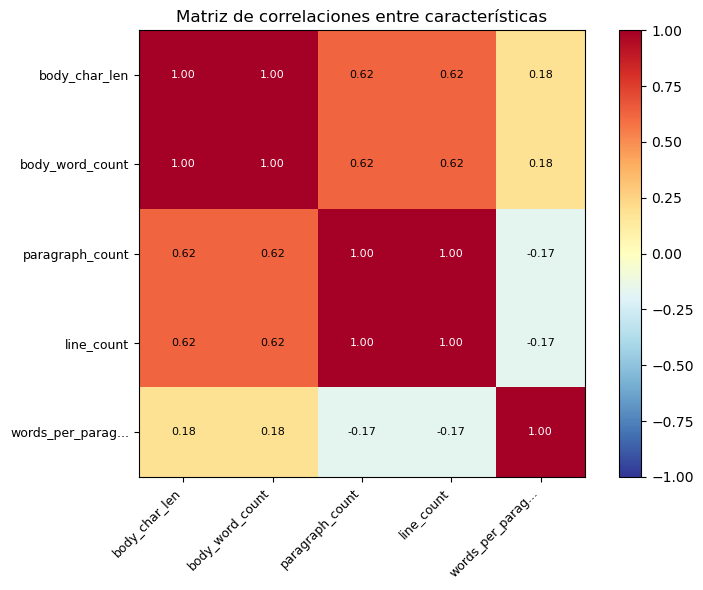

In [76]:
fig, ax = plt.subplots(figsize=(8, 6))
labels = ['body_char_len', 'body_word_count', 'paragraph_count', 'line_count', 'words_per_paragraph']
im = ax.imshow(corr[labels].values, cmap='RdYlBu_r', vmin=-1, vmax=1)
ax.set_xticks(range(len(labels)))
ax.set_yticks(range(len(labels)))
ax.set_xticklabels([l[:15] + '...' if len(l) > 15 else l for l in labels], rotation=45, ha='right', fontsize=9)
ax.set_yticklabels([l[:15] + '...' if len(l) > 15 else l for l in labels], fontsize=9)

for i in range(len(labels)):
    for j in range(len(labels)):
        ax.text(j, i, f'{corr[labels].values[i, j]:.2f}', ha='center', va='center', 
                fontsize=8, color='black' if abs(corr[labels].values[i, j]) < 0.7 else 'white')

plt.colorbar(im, ax=ax)
plt.title('Matriz de correlaciones entre características')
plt.tight_layout()
plt.show()

## 17. Resumen del EDA

In [ ]:
print('=' * 80)
print('RESUMEN DEL EXPLORATORY DATA ANALYSIS')
print('=' * 80)
print()
print(f'Archivo: {file_name}')
print(f'Cantidad total de noticias: {len(df):,}')
print(f'Cantidad de medios: {df["media_name"].nunique():,}')
print(f'Noticias con fecha válida: {df["date"].notna().sum():,} ({df["date"].notna().mean()*100:.1f}%)')
print(f'Noticias con autor: {df["author"].notna().sum():,} ({df["author"].notna().mean()*100:.1f}%)')
print()
print('=== Características de textos ===')
print(f'Longitud mediana (caracteres): {df["body_char_len"].median():.0f}')
print(f'Longitud mediana (palabras): {df["body_word_count"].median():.0f}')
print(f'Párrafos mediana: {df["paragraph_count"].median():.1f}')
print()
print('=== Calidad de datos ===')
dates_valid = df['date'].dropna()
print(f'Fechas antes de 2000: {(dates_valid < "2000-01-01").sum()}')
print(f'Fechas después de 2030: {(dates_valid > "2030-12-31").sum()}')
print(f'Textos con menos de 10 palabras: {(df["body_word_count"] < 10).sum()}')
print(f'Textos con HTML: {df["has_html"].sum()} ({df["has_html"].mean()*100:.1f}%)')
print(f'Textos con URLs: {df["has_urls"].sum()} ({df["has_urls"].mean()*100:.1f}%)')
print()
print('=== Medios principales (top 5) ===')
for media, count in df['media_name'].value_counts().head(5).items():
    print(f'  {media}: {count:,} noticias')
print()
print('=== Autores principales (top 5) ===')
for author, count in df['author'].value_counts().head(5).items():
    print(f'  {author}: {count:,} artículos')
print('=' * 80)